# Рынок общественного питания Москвы

### Цели и задачи проекта

**Цель:** Провести исследовательский анализ рынка общественного питания Москвы для инвесторов из фонда Shut Up and Take My Money. Результаты будут использованы в выборе подходящего инвесторам места при открытии заведения общественного питания.

**Задачи:**
1. Загрузить данные и познакомиться с их содержимым
2. Провести предобработку данных
3. Провести исследовательский анализ данных:
    - изучить данные более детально
    - проанализировать распределение заведений по категориям и административным округам Москвы
    - соотнести сетевые и несетевые заведения, количество посадочных мест
    - исследовать рейтинг
    - провести анализ корреляции данных
    - найти топ-15 популярных сетей в Москве
    - изучить вариацию среднего чека заведения
4. Сформулировать выводы по проведённому анализу

### Описание данных

Для анализа поступили данные заведений общественного питания Москвы, составленные на основе данных сервисов Яндекс Карты и Яндекс Бизнес на лето 2022 года. Информация, размещённая в сервисе Яндекс Бизнес, могла быть добавлена пользователями или найдена в общедоступных источниках. Она носит исключительно справочный характер. Данные состоят из двух датасетов:

- `rest_info.csv` — информация о заведениях общественного питания
- `rest_price.csv` —  информация о среднем чеке в заведениях общественного питания

### Описание датасета `rest_info`

- `name` — название заведения
- `address` — адрес заведения
- `district` — административный район, в котором находится заведение, например Центральный административный округ
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»
- `hours` — информация о днях и часах работы
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0)
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки)
    - `0` — заведение не является сетевым
    - `1` — заведение является сетевым
- `seats` — количество посадочных мест

### Описание датасета `rest_price`

- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее
- `avg_bill` — строка, которая хранит среднюю стоимость заказа в виде диапазона, например:
    - «Средний счёт: 1000–1500 ₽»
    - «Цена чашки капучино: 130–220 ₽»
    - «Цена бокала пива: 400–600 ₽»
    - и т. д.
- `middle_avg_bill` — число с оценкой одной чашки капучино, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки «Цена одной чашки капучино»
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число
    - Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки «Цена одной чашки капучино»:
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число
    - Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт

### Содержимое проекта

1. Загрузка данных и знакомство с ними
2. Предобработка данных
3. Исследовательский анализ данных
4. Итоговые выводы

---

## Загрузка данных и знакомство с ними

Загрузим данные о заведениях общественного питания Москвы. Путь к файлам: `/datasets/rest_info.csv` и `/datasets/rest_price.csv`. Подключим необходимые для работы библиотеки

In [2]:
!pip install phik==0.11.0

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix

In [4]:
rest_info_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
rest_price_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')

Ознакомимся с данными датасета `rest_info_df`, он содержит информацию о заведениях общественного питания. Изучим его – выведем информацию о датафрейме методом `info()`, первые и последние строки методом `head()` и `tail()`, изучим значения некоторых столбцов

In [5]:
rest_info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [6]:
rest_info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [7]:
rest_info_df.tail()

,id,name,category,address,district,hours,rating,chain,seats
8401,0342ad1a45ed41ba89dcba246a8267e5,Суши Мания,кафе,"Москва, Профсоюзная улица, 56",Юго-Западный административный округ,"ежедневно, 09:00–02:00",4.4,0,86.0
8402,ee6bb7c3650e47bd8186fca08eda1091,Миславнес,кафе,"Москва, Пролетарский проспект, 19, корп. 1",Южный административный округ,"ежедневно, 08:00–22:00",4.8,0,150.0
8403,62e8c64d4c89467aba608e39ef87616b,Самовар,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",3.9,0,150.0
8404,06a0db5ecd4842d48cd6350aa923e297,Чайхана Sabr,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",4.2,1,150.0
8405,9d56f8f7a7f74df1a925bc0fd2de8aae,Kebab Time,кафе,"Москва, Россошанский проезд, 6",Южный административный округ,"ежедневно, круглосуточно",3.9,0,12.0


Проверим пропуски

In [8]:
rest_info_df.isna().sum()

id             0
name           0
category       0
address        0
district       0
hours        536
rating         0
chain          0
seats       3611
dtype: int64

In [9]:
rest_info_df.isna().mean() * 100

id           0.000000
name         0.000000
category     0.000000
address      0.000000
district     0.000000
hours        6.376398
rating       0.000000
chain        0.000000
seats       42.957411
dtype: float64

In [10]:
rest_info_df['category'].unique()

array(['кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб',
       'быстрое питание', 'булочная', 'столовая'], dtype=object)

In [11]:
rest_info_df['chain'].unique()

array([0, 1])

In [12]:
rest_info_df['district'].unique()

array(['Северный административный округ',
       'Северо-Восточный административный округ',
       'Северо-Западный административный округ',
       'Западный административный округ',
       'Центральный административный округ',
       'Восточный административный округ',
       'Юго-Восточный административный округ',
       'Южный административный округ',
       'Юго-Западный административный округ'], dtype=object)

In [13]:
rest_info_df['hours'].unique()

array(['ежедневно, 10:00–22:00',
       'пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00–02:00',
       'ежедневно, 09:00–22:00', ...,
       'пн-пт 08:30–21:30; сб,вс 09:00–21:30',
       'пн-чт 13:00–22:00; пт,сб 13:00–22:30; вс 13:00–22:00',
       'пн-сб 10:30–21:30'], dtype=object)

Проделаем то же самое с данными датасета `rest_price_df`, он содержит информацию о среднем чеке в заведениях общественного питания

In [14]:
rest_price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


In [15]:
rest_price_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [16]:
rest_price_df.tail()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
4053,962800540173458486f3c465437c2d8b,средние,Цена бокала пива:от 140 ₽,NaN,NaN
4054,4277890d659341848d7051cbf2e51f51,выше среднего,Средний счёт:1000–1500 ₽,1250.0,NaN
4055,026cbc478f9b4c3294a83458dcd89982,средние,NaN,NaN,NaN
4056,71cc394927204d45b81c3a91edb47955,NaN,Средний счёт:50–250 ₽,150.0,NaN
4057,62e8c64d4c89467aba608e39ef87616b,NaN,Средний счёт:от 150 ₽,150.0,NaN


In [157]:
rest_price_df.isna().sum().sort_values(ascending = False)

middle_coffee_cup    3523
middle_avg_bill       909
price                 743
avg_bill              242
id                      0
dtype: int64

In [158]:
rest_price_df.isna().mean().sort_values(ascending = False) * 100

middle_coffee_cup    86.816166
middle_avg_bill      22.400197
price                18.309512
avg_bill              5.963529
id                    0.000000
dtype: float64

In [19]:
rest_price_df['price'].unique()

array(['выше среднего', 'средние', nan, 'высокие', 'низкие'], dtype=object)

In [20]:
rest_price_df['middle_avg_bill'].value_counts()

1250.0    247
1000.0    175
300.0     148
1500.0    146
400.0     134
         ... 
383.0       1
255.0       1
67.0        1
495.0       1
107.0       1
Name: middle_avg_bill, Length: 230, dtype: int64

In [21]:
rest_price_df['middle_coffee_cup'].value_counts()

256.0    43
60.0     33
95.0     32
150.0    24
170.0    18
         ..
137.0     1
315.0     1
167.0     1
169.0     1
129.0     1
Name: middle_coffee_cup, Length: 96, dtype: int64

---

### Промежуточный вывод

После ознакомления сделаем промежуточный вывод о полученных данных

Датасет `rest_info_df` содержит 9 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания. Данные соответствуют ли данные описанию. У столбца `hours` странные значения (дни и время работы заведений), посмотрим от чего это зависит. Названия столбцов соответствуют виду snake case. Судя по выгрузке вариантов, которые содержит столбец `chain`, можно привести его тип данных к булевому. В столбце `id` пропусков нет, но они содержатся в столбцах `hours` (6% пустых значений) и `seats` (43% пустых значений). В последнем восстановить данные точно не получится из-за объёма данных + проверить, можно ли заменить тип на `int`. У столбца `rating` и других можно понизить разрядность

Датасет `rest_price_df` содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведениях общественного питания. Данные соответствуют ли данные описанию. Названия столбцов соответствуют виду snake case. Пропуски содержатся во всех столбцах, кроме `id` (в `middle_coffee_cup` потеря доходить до 87%). Похоже в столбце `middle_avg_bill` и `middle_coffee_cup` содержатся только целочисленные значения, поменяем тип на `int`

### Подготовка единого датафрейма

Объединим данные двух датасетов в один `df`, с которым продолжим работу. Объединять будем по левому джойну, так как правый  датафрейм в 2 раза меньше левого, и по левому будет проводиться основная часть анализа (изучение данных района, мест и т. д.)

In [22]:
df = rest_info_df.merge(rest_price_df, on = 'id', how = 'left')

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


In [24]:
df.head(10)

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN
5,8a343546b24e4a499ad96eb7d0797a8a,Sergio Pizza,пиццерия,"Москва, Ижорская улица, вл8Б",Северный административный округ,"ежедневно, 10:00–23:00",4.6,0,NaN,средние,NaN,NaN,NaN
6,96ebceb1a09e4e3191133b9fe0379a64,Огни города,"бар,паб","Москва, Клязьминская улица, 9, стр. 3",Северный административный округ,пн 15:00–04:00; вт-вс 15:00–05:00,4.4,0,45.0,средние,Средний счёт:199 ₽,199.0,NaN
7,0243288b78024af090b8e947842c969c,Mr. Уголёк,быстрое питание,"Москва, Клязьминская улица, 9, стр. 3",Северный административный округ,"пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...",4.7,0,45.0,средние,Средний счёт:200–300 ₽,250.0,NaN
8,36aeb0ffa69c48fdb0021549520deb10,Donna Maria,ресторан,"Москва, Дмитровское шоссе, 107, корп. 4",Северный административный округ,"ежедневно, 10:00–22:00",4.8,0,79.0,средние,Средний счёт:от 500 ₽,500.0,NaN
9,487167877eb04288bc90d4fa80646fc2,Готика,кафе,"Москва, Ангарская улица, 39",Северный административный округ,"ежедневно, 12:00–00:00",4.3,0,65.0,средние,Средний счёт:1000–1200 ₽,1100.0,NaN


In [25]:
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [26]:
df.isna().mean() * 100

id                    0.000000
name                  0.000000
category              0.000000
address               0.000000
district              0.000000
hours                 6.376398
rating                0.000000
chain                 0.000000
seats                42.957411
price                60.563883
avg_bill             54.603854
middle_avg_bill      62.538663
middle_coffee_cup    93.635498
dtype: float64

In [27]:
initial_row_count = df.shape[0]

Получился датафрейм `df`, в котором 8406 строк и 13 столбцов

---

## Предобработка данных

Подготовим данные к исследовательскому анализу

Скорректируем типы данных (преобразуем и оптимизируем). В `id` содержатся буквенные значения, этот и столбцы `name`, `category`, `address`, `district`, `hours`, `price`, `avg_bill` с типом данных object. Столбец `chain` приведём к логическому типу. `seats`, `middle_avg_bill`, `middle_coffee_cup` к int (пропуски в этих столбцах заполним маркерами -1, их слишком много для удаления).

In [28]:
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                  int64
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

In [29]:
df['chain'] = df['chain'].astype(bool)

In [30]:
for column in ['seats', 'middle_avg_bill', 'middle_coffee_cup']:
    df[column] = df[column].fillna(-1)
    df[column] = pd.to_numeric(df[column], downcast = 'integer')
    
df['rating'] = pd.to_numeric(df['rating'], downcast = 'float')

In [31]:
df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float32
chain                   bool
seats                  int16
price                 object
avg_bill              object
middle_avg_bill        int32
middle_coffee_cup      int16
dtype: object

Пропусков в столбце `hours` 6.38%, слишком много для удаления. Данные в этом столбце не связаны с другими (нет зависимости от, например, столбца `category`, вариантов заполнения огромное количество), а скорее с данными, которых нет в датафрейме (не заполнили время составления). Оставим пропуски как есть

In [32]:
unique_cafe_hours = df[df['category'] == 'кафе']['hours'].unique()
unique_cafe_hours

array(['ежедневно, 10:00–22:00',
       'пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00–02:00',
       'ежедневно, 12:00–00:00', 'ежедневно, 10:00–21:00',
       'вт-сб 09:00–18:00', 'ежедневно, 10:00–23:00', 'пн-пт 09:00–21:00',
       'ежедневно, круглосуточно', 'ежедневно, 10:00–19:00',
       'ежедневно, 08:00–23:00', nan, 'ежедневно, 11:00–00:00',
       'ежедневно, 09:00–02:00', 'ежедневно, 12:00–23:00',
       'ежедневно, 16:00–06:00', 'пн-сб 11:00–23:00; вс 12:00–23:00',
       'пн-пт 10:00–21:00; сб,вс 10:00–22:00',
       'пн-чт 12:00–03:00; пт,сб 12:00–04:30; вс 12:00–03:00',
       'ежедневно, 09:00–06:00', 'ежедневно, 10:00–21:30',
       'ежедневно, 09:00–22:00', 'ежедневно, 06:00–20:00',
       'ежедневно, 10:30–23:00', 'ежедневно, 10:00–20:00',
       'ежедневно, 07:00–00:00', 'ежедневно, 08:00–00:00',
       'пн-пт 09:00–16:00', 'пн-чт 08:00–20:00; пт-вс 10:00–22:00',
       'ежедневно, 11:00–23:00',
       'пн-чт 12:00–02:00; пт,сб 12:00–04:00; вс 12:00–02:00',
      

In [33]:
unique_cafe_hours = df[df['category'] == 'бар,паб']['hours'].unique()
unique_cafe_hours

array(['пн 15:00–04:00; вт-вс 15:00–05:00', 'ежедневно, круглосуточно',
       'ежедневно, 13:00–00:00', 'ежедневно, 12:00–03:00',
       'пн-чт 12:30–00:00; пт,сб 12:30–02:00; вс 12:30–00:00',
       'ежедневно, 11:00–23:00',
       'пн-чт 14:00–00:00; пт,сб 14:00–02:00; вс 14:00–00:00', nan,
       'ежедневно, 10:00–22:00', 'ежедневно, 08:00–23:00',
       'ежедневно, 13:00–04:00', 'пн-пт 11:00–05:00; сб,вс 12:00–05:00',
       'пн-чт 11:00–00:00; пт-вс 11:00–05:00', 'ежедневно, 11:00–00:00',
       'пн-пт 11:00–23:00; сб,вс 10:00–23:00',
       'пн-чт 10:00–23:00; пт,сб 10:00–02:00; вс 10:00–23:00',
       'пн-чт 12:00–00:00; пт-вс 12:00–01:00',
       'пн-чт 12:00–00:00; пт,сб 12:00–02:00; вс 12:00–00:00',
       'пн-пт 11:00–23:00; сб,вс 12:00–23:00',
       'пн-чт 12:00–01:00; пт,сб 12:00–02:00; вс 12:00–01:00',
       'ежедневно, 12:00–05:00', 'ежедневно, 12:00–02:00',
       'ежедневно, 12:00–01:00', 'ежедневно, 12:00–00:00',
       'пн-чт 11:00–00:00; пт,сб 12:00–03:00; вс 11:

In [34]:
unique_cafe_hours = df[df['category'] == 'быстрое питание']['hours'].unique()
unique_cafe_hours

array(['пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00–22:00',
       'пн-пт 08:00–22:00; сб,вс 10:00–22:00', 'ежедневно, 10:00–22:00',
       'ежедневно, 09:00–23:00', 'ежедневно, круглосуточно', nan,
       'вт-вс 09:00–19:00', 'ежедневно, 10:00–21:30', 'пн-пт 09:00–16:00',
       'ежедневно, 10:00–20:00', 'ежедневно, 11:00–23:00',
       'ежедневно, 08:00–23:00', 'ежедневно, 10:00–01:00',
       'ежедневно, 07:30–00:30', 'ежедневно, 09:00–23:45',
       'ежедневно, 08:00–22:00', 'ежедневно, 10:00–00:00',
       'ежедневно, 10:00–21:00', 'ежедневно, 09:00–22:00',
       'ежедневно, 09:00–00:00', 'ежедневно, 09:00–21:00',
       'ежедневно, 10:00–23:00', 'ежедневно, 11:00–00:00',
       'ежедневно, 08:00–19:30', 'ежедневно, 07:00–23:00',
       'пн-чт 07:00–23:00; пт,сб 08:00–01:00; вс 08:00–23:00',
       'пн-сб 08:00–21:00; вс 08:00–20:30',
       'пн-чт 11:00–20:00; пт-вс 10:00–20:00', 'ежедневно, 11:00–20:00',
       'ежедневно, 11:00–22:00', 'пн-сб 08:00–20:00',
       'пн-пт 08:

In [35]:
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                   0
price                5091
avg_bill             4590
middle_avg_bill         0
middle_coffee_cup       0
dtype: int64

In [36]:
df.isna().mean() * 100

id                    0.000000
name                  0.000000
category              0.000000
address               0.000000
district              0.000000
hours                 6.376398
rating                0.000000
chain                 0.000000
seats                 0.000000
price                60.563883
avg_bill             54.603854
middle_avg_bill       0.000000
middle_coffee_cup     0.000000
dtype: float64

Проверим данные на явные и неявные дубликаты, поля с названием и адресом заведения

In [37]:
df.duplicated().sum()

0

Проверим значения столбца `id`

In [38]:
df.duplicated(subset = 'id').sum()

0

Большое количество дупликатов в названиях заведений и адресах. Проверим их, и как они связаны со столбцом `chain`

In [39]:
df.duplicated(subset = 'name').sum()

2792

In [40]:
df['name'].unique()

array(['WoWфли', 'Четыре комнаты', 'Хазри', ..., 'Миславнес', 'Самовар',
       'Kebab Time'], dtype=object)

In [41]:
df['name'].nunique()

5614

In [42]:
df['chain'].sum()

3205

Посмотрим на глубину адреса в датафрейме

In [43]:
df.loc[30]

id                       a5536f9643c94da1988cc5cca91a5ee7
name                                              Кафедра
category                                         булочная
address              Москва, Базовская улица, 15, корп. 6
district                  Северный административный округ
hours                              ежедневно, 08:00–21:00
rating                                                4.4
chain                                               False
seats                                                  -1
price                                                 NaN
avg_bill                                              NaN
middle_avg_bill                                        -1
middle_coffee_cup                                      -1
Name: 30, dtype: object

In [44]:
df.loc[300]

id                          f6623b42d3e243edba11e135e9b024e9
name                                        Ресторан Стейк'S
category                                            ресторан
address              Москва, Ленинградское шоссе, 80, стр. 1
district                     Северный административный округ
hours                                 ежедневно, 12:00–23:00
rating                                                   4.6
chain                                                  False
seats                                                     84
price                                                высокие
avg_bill                                                 NaN
middle_avg_bill                                           -1
middle_coffee_cup                                         -1
Name: 300, dtype: object

Адрес точен до дома, в одном здании/корпусе может находиться несколько заведений общественного питания

In [45]:
df.duplicated(subset = 'address').sum()

2653

In [46]:
df['address'].unique()

array(['Москва, улица Дыбенко, 7/1', 'Москва, улица Дыбенко, 36, корп. 1',
       'Москва, Клязьминская улица, 15', ...,
       'Москва, улица Лобачевского, 52, корп. 1',
       'Москва, Болотниковская улица, 52, корп. 2',
       'Москва, Чонгарский бульвар, 26А, корп. 1'], dtype=object)

In [47]:
df['address'].nunique()

5753

In [48]:
dupl = df['name'].value_counts()
dupl_count = dupl[dupl > 1]
dupl_count

Кафе                189
Шоколадница         120
Домино'с Пицца       76
Додо Пицца           74
One Price Coffee     71
                   ... 
Temple Bar            2
Pho Hanoi             2
Бизнес-кафе           2
One Special           2
The Hummus            2
Name: name, Length: 714, dtype: int64

Проверим, все ли дубли заведений являются сетями

In [49]:
dupl = df['name'].value_counts()
dupl_count = dupl[dupl > 1]
dupl_count

Кафе                189
Шоколадница         120
Домино'с Пицца       76
Додо Пицца           74
One Price Coffee     71
                   ... 
Temple Bar            2
Pho Hanoi             2
Бизнес-кафе           2
One Special           2
The Hummus            2
Name: name, Length: 714, dtype: int64

In [50]:
only_chain = df[df['chain'] == True]
dupl = only_chain['name'].value_counts()
dupl_count = dupl[dupl > 1]
dupl_count

Шоколадница            120
Домино'с Пицца          76
Додо Пицца              74
One Price Coffee        71
Яндекс Лавка            69
                      ... 
Manny's Burger           2
Французская пекарня      2
Gump's                   2
Arcus Bar And Food       2
Demi Coffee Shop         2
Name: name, Length: 698, dtype: int64

In [51]:
only_chain = df[df['chain'] == False]
dupl = only_chain['name'].value_counts()
dupl_count = dupl[dupl > 1]
dupl_count

Кафе                 189
Шаурма                43
Ресторан              34
Столовая              28
Кофейня               12
Бистро                12
Кафе-столовая          9
Буфет                  8
Трапезная              7
Шашлычная              6
Поминальные обеды      5
Блины                  3
Пиццерия               3
Кафе для поминок       2
Чебуречная             2
Кафе-кулинария         2
Name: name, dtype: int64

In [52]:
df.loc[df['name'] == 'Поминальные обеды']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
597,e99e0290a66840d1a3a047ea1c9db4a4,Поминальные обеды,кафе,"Москва, улица Вилиса Лациса, 13, корп. 1",Северо-Западный административный округ,"ежедневно, 09:00–23:00",2.9,False,120,высокие,Средний счёт:1500–2500 ₽,2000,-1
5447,e97aad45f22d46bf86212867c59aec68,Поминальные обеды,кафе,"Москва, Перовская улица, 66, корп. 4",Восточный административный округ,"ежедневно, 09:00–23:00",3.0,False,32,высокие,Средний счёт:1500–2500 ₽,2000,-1
6610,c9f70f46d4774fdc9ce94174c566e0e7,Поминальные обеды,кафе,"Москва, проспект Вернадского, 113",Западный административный округ,"ежедневно, 09:00–23:00",4.3,False,-1,высокие,Средний счёт:1500–2500 ₽,2000,-1
6611,e19ba2aab83f41d289f84f0d9dc4058c,Поминальные обеды,кафе,"Москва, улица Академика Анохина, 56",Западный административный округ,"ежедневно, 10:00–21:00",4.1,False,36,выше среднего,Средний счёт:1000–1500 ₽,1250,-1
7024,01de64a1fdcf4f5eaa9ebe7f16428b11,Поминальные обеды,кафе,"Москва, Профсоюзная улица, 39",Юго-Западный административный округ,"ежедневно, 09:00–23:00",3.6,False,-1,NaN,Средний счёт:1500–2500 ₽,2000,-1


In [53]:
df.loc[df['name'] == 'Пион']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
3983,c9898f0e5f5c4e1c8a4bbea0d82c99d4,Пион,кафе,"Москва, Кутузовский проспект, 21",Западный административный округ,пн 13:00–00:00; вт-вс 10:00–00:00,4.4,True,40,NaN,NaN,-1,-1
6315,728b11f0515b415d98893c8b7abd3942,Пион,кафе,"Москва, Центральный парк культуры и отдыха име...",Центральный административный округ,"ежедневно, 10:00–00:00",4.9,True,-1,NaN,NaN,-1,-1


In [54]:
df.loc[df['name'] == 'Бистро']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
645,49ab9430a2f744d6809ccebd446ef602,Бистро,быстрое питание,"Москва, Тушинская улица, 17",Северо-Западный административный округ,"ежедневно, круглосуточно",3.5,False,90,NaN,NaN,-1,-1
1204,ff524db62a524c099726889f1148282d,Бистро,кафе,"Москва, Северо-Западный административный округ...",Северо-Западный административный округ,"ежедневно, 10:00–20:30",4.9,False,-1,NaN,NaN,-1,-1
2370,0ff7ef8133b74e2699c5896b8877c1da,Бистро,кафе,"Москва, улица Цандера, 7, корп. 2А",Северо-Восточный административный округ,"ежедневно, круглосуточно",4.1,False,-1,NaN,NaN,-1,-1
2461,4b15cdb748b8491abb1bf5f02024a225,Бистро,"бар,паб","Москва, Краснопрудная улица, 1",Центральный административный округ,"ежедневно, круглосуточно",3.6,False,80,NaN,NaN,-1,-1
2503,8c02b3abca09430baf77b293b5c455f5,Бистро,кафе,"Москва, Сокольническая площадь, 4к1-2",Восточный административный округ,"ежедневно, круглосуточно",4.1,False,-1,NaN,NaN,-1,-1
3061,2fbfdc78f76c410588cdeec46b6741fa,Бистро,кафе,"Москва, улица Академика Павлова, 50",Западный административный округ,"ежедневно, 08:00–22:00",3.6,False,-1,NaN,NaN,-1,-1
5235,93b374c8043843a68cb6667969c65f2f,Бистро,быстрое питание,"Москва, Пятницкий переулок, 2",Центральный административный округ,"пн-пт 09:00–20:00; сб,вс 09:00–19:00",4.3,False,70,NaN,NaN,-1,-1
5999,81bbd3438bb44d3288a6750de373ba91,Бистро,кафе,"Москва, улица Доватора, 13, стр. 2",Центральный административный округ,"ежедневно, 10:00–22:00",4.3,False,-1,средние,NaN,-1,-1
6244,4de59b9bbcb94c04b3bac276a0acb4d0,Бистро,быстрое питание,"Москва, улица Панфёрова, 3, стр. 1",Юго-Западный административный округ,"ежедневно, круглосуточно",4.3,False,76,NaN,NaN,-1,-1
6491,79bebd53d0154c6893d5d8cfbf41082d,Бистро,быстрое питание,"Москва, Люблинская улица, 10с4",Юго-Восточный административный округ,"ежедневно, круглосуточно",3.6,False,-1,NaN,NaN,-1,-1


Есть много заведений с одинаковыми названиями, которые не помечены как сети, но у них несколько точек. Такое может быть, если нет стандартизации, управление независимое или у них разные юридические лица. В некоторых строках названий точек как таковых нет (возможно сбой или человеческий фактор), но разные адреса, их оставим. Удалим совпадения и по названию заведения, и по адресу

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float32
 7   chain              8406 non-null   bool   
 8   seats              8406 non-null   int16  
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    8406 non-null   int32  
 12  middle_coffee_cup  8406 non-null   int16  
dtypes: bool(1), float32(1), int16(2), int32(1), object(8)
memory usage: 955.8+ KB


In [56]:
mask = df.duplicated(subset = ['name', 'address'], keep = False)
dupl = df[mask]
dupl

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup


Дупликатов и по имени и по адресу нет

In [57]:
dupl = df['address'].value_counts()
dupl_count = dupl[dupl > 1]
dupl_count

Москва, проспект Вернадского, 86В          28
Москва, Усачёва улица, 26                  26
Москва, площадь Киевского Вокзала, 2       20
Москва, Ярцевская улица, 19                20
Москва, Каширское шоссе, 61Г               16
                                           ..
Москва, Гостиничная улица, 5                2
Москва, улица Генерала Белова, 1/8          2
Москва, Коптевская улица, 65А               2
Москва, Каширское шоссе, 96, корп. 1        2
Москва, бульвар Генерала Карбышева, 13А     2
Name: address, Length: 1357, dtype: int64

Проверим, например, адрес `Москва, проспект Вернадского, 86В`. Проверим адрес по карте - это фудкорт

In [58]:
df.loc[df['address'] == 'Москва, проспект Вернадского, 86В']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
6531,3dec8b6d8ff54cad9e83668176e21985,Паrk фудхолл,"бар,паб","Москва, проспект Вернадского, 86В",Западный административный округ,"пн-чт 10:00–23:00; пт,сб 10:00–00:00; вс 11:00...",4.6,False,-1,NaN,NaN,-1,-1
6532,dfe8feb83ce340e2ac3edddf14eb0dbd,I Need Doner,ресторан,"Москва, проспект Вернадского, 86В",Западный административный округ,"пн-чт 10:00–23:00; пт,сб 10:00–00:00; вс 10:00...",4.9,True,-1,NaN,Средний счёт:400–700 ₽,550,-1
6534,0a192afa3b834d4d9384d922cccca548,Fibo Pasta & Ravioli,кафе,"Москва, проспект Вернадского, 86В",Западный административный округ,пн-сб 10:00–22:00; вс 11:00–22:00,4.8,True,-1,средние,Средний счёт:500–1000 ₽,750,-1
6547,71623b79646845dab55d37ef0f126861,Сыроварня,ресторан,"Москва, проспект Вернадского, 86В",Западный административный округ,"ежедневно, 11:00–23:00",4.5,True,-1,высокие,Средний счёт:2000–2500 ₽,2250,-1
6549,ed8da8dc33034f20a750e89189a833e6,Bổ,кафе,"Москва, проспект Вернадского, 86В",Западный административный округ,"пн-чт 10:00–23:00; пт,сб 10:00–00:00; вс 11:00...",4.7,False,-1,NaN,NaN,-1,-1
6568,f5172204de9b4b3fb74beb98e5a5f8ca,Aly’s Poke,ресторан,"Москва, проспект Вернадского, 86В",Западный административный округ,"пн-чт 10:00–23:00; пт,сб 10:00–00:00; вс 11:00...",4.6,False,-1,средние,Средний счёт:390–660 ₽,525,-1
6584,ec9dd69372df4ea7970ac12fc1a02573,Курица и Утка по-Гонконгски,ресторан,"Москва, проспект Вернадского, 86В",Западный административный округ,"ежедневно, 11:00–23:00",4.3,False,-1,NaN,NaN,-1,-1
6597,fe05fed76caf474e9005f5c2f4c31121,Асса Food,ресторан,"Москва, проспект Вернадского, 86В",Западный административный округ,"пн-чт 10:00–23:00; пт,сб 10:00–00:00; вс 11:00...",4.3,False,-1,NaN,NaN,-1,-1
6604,36b0becc10804fd897af9bf9855c0bfc,Shrimp Kitchen,ресторан,"Москва, проспект Вернадского, 86В",Западный административный округ,"пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...",4.4,False,-1,выше среднего,Средний счёт:1000–1500 ₽,1250,-1
6630,7cbcc96d11cc4fbeb39404be1b283420,Мясоед,ресторан,"Москва, проспект Вернадского, 86В",Западный административный округ,"пн-чт 10:00–23:00; пт,сб 10:00–00:00; вс 11:00...",4.2,False,-1,NaN,NaN,-1,-1


Проверим адрес `Москва, улица Преображенский Вал, 27`. Похоже веранду ресторана вынесли в отдельную строку (в здании на карте только одно заведение). Но рейтинг у них разный. Это вносит диссонанс

In [59]:
df.loc[df['address'] == 'Москва, улица Преображенский Вал, 27']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
2834,f297b50b12574fda85cd9753d2ba278f,Ресторан,ресторан,"Москва, улица Преображенский Вал, 27",Восточный административный округ,NaN,4.4,False,98,NaN,NaN,-1,-1
2900,2f1c3d81a6b04e56ad063418ae3c9a0b,Летняя веранда,ресторан,"Москва, улица Преображенский Вал, 27",Восточный административный округ,"ежедневно, 11:00–23:00",4.1,True,98,NaN,NaN,-1,-1


In [60]:
df.loc[df['name'] == 'Летняя веранда']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
2839,d0dc9707643543b4b9981e3f4b373fa8,Летняя веранда,ресторан,"Москва, Краснобогатырская улица, 72, стр. 19",Восточный административный округ,"ежедневно, 11:00–00:00",4.2,True,-1,выше среднего,NaN,-1,-1
2900,2f1c3d81a6b04e56ad063418ae3c9a0b,Летняя веранда,ресторан,"Москва, улица Преображенский Вал, 27",Восточный административный округ,"ежедневно, 11:00–23:00",4.1,True,98,NaN,NaN,-1,-1
7094,eace8fbadf104230b030ac0c72f6d7c3,Летняя веранда,кафе,"Москва, музей-заповедник Коломенское",Южный административный округ,"ежедневно, 10:00–22:00",5.0,True,-1,NaN,NaN,-1,-1


In [61]:
df.loc[df['address'] == 'Москва, музей-заповедник Коломенское']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
7094,eace8fbadf104230b030ac0c72f6d7c3,Летняя веранда,кафе,"Москва, музей-заповедник Коломенское",Южный административный округ,"ежедневно, 10:00–22:00",5.0,True,-1,NaN,NaN,-1,-1
7144,3c9f2c53dbd44e6ca9fd030afa04aeb8,Аммбар,ресторан,"Москва, музей-заповедник Коломенское",Южный административный округ,"ежедневно, 10:00–22:00",5.0,False,-1,NaN,NaN,-1,-1
7206,ec4759ee4d0f4541aa4fba5c580e733b,Ваниль,кафе,"Москва, музей-заповедник Коломенское",Южный административный округ,NaN,5.0,False,-1,NaN,NaN,-1,-1


In [62]:
df.loc[df['address'] == 'Москва, улица Пришвина, 3Б']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
83,3600433de76141358e853bbe3d92a089,Аль-Бухари,кафе,"Москва, улица Пришвина, 3Б",Северо-Восточный административный округ,"ежедневно, 09:00–02:00",4.3,False,50,NaN,NaN,-1,-1
168,caf0b734919740a7a64285b38742eeb9,Шаурма на углях,кафе,"Москва, улица Пришвина, 3Б",Северо-Восточный административный округ,"ежедневно, 09:00–22:00",4.1,True,50,NaN,NaN,-1,-1


Удалим все летние веранды

In [63]:
df = df[df['name'] != 'Летняя веранда']

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8403 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8403 non-null   object 
 1   name               8403 non-null   object 
 2   category           8403 non-null   object 
 3   address            8403 non-null   object 
 4   district           8403 non-null   object 
 5   hours              7867 non-null   object 
 6   rating             8403 non-null   float32
 7   chain              8403 non-null   bool   
 8   seats              8403 non-null   int16  
 9   price              3314 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    8403 non-null   int32  
 12  middle_coffee_cup  8403 non-null   int16  
dtypes: bool(1), float32(1), int16(2), int32(1), object(8)
memory usage: 697.5+ KB


Нормализуем все текстовые значения

In [65]:
for column in ['name', 'category', 'address', 'district', 'hours', 'price', 'avg_bill']:
    df[column] = df[column].str.lower()
    df[column] = df[column].str.strip()

In [66]:
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",северный административный округ,"ежедневно, 10:00–22:00",5.0,False,-1,NaN,NaN,-1,-1
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный административный округ,"ежедневно, 10:00–22:00",4.5,False,4,выше среднего,средний счёт:1500–1600 ₽,1550,-1
2,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,False,45,средние,средний счёт:от 1000 ₽,1000,-1
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",северный административный округ,"ежедневно, 09:00–22:00",5.0,False,-1,NaN,цена чашки капучино:155–185 ₽,-1,170
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный административный округ,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1


Для дальнейшей работы создадим столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно
  - логическое значение `False` — в противоположном случае

In [67]:
time = r'круглосуточно|24/7|24\\7|24 часа'
df['is_24_7'] = df['hours'].str.contains(time, case = False, na = False)

In [68]:
df.loc[df['hours'] == 'ежедневно, круглосуточно']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
10,ac32978af97641bfacf996e7f5a50ee5,great room bar,"бар,паб","москва, левобережная улица, 12",северный административный округ,"ежедневно, круглосуточно",4.5,False,102,средние,цена бокала пива:250–350 ₽,-1,-1,True
17,b55465d0869648a295ad1d85ed9b5c4f,чайхана беш-бармак,ресторан,"москва, ленинградское шоссе, 71б, стр. 2",северный административный округ,"ежедневно, круглосуточно",4.4,False,96,средние,средний счёт:350–500 ₽,425,-1,True
19,feec6bedccae44cb877d99c13f9aa5d7,пекарня,булочная,"москва, ижорский проезд, 5",северный административный округ,"ежедневно, круглосуточно",4.4,True,-1,NaN,NaN,-1,-1,True
24,0f5d22f5377340d0a81a9328e6ebdcac,drive café,кафе,"москва, улица дыбенко, 9ас1",северный административный округ,"ежедневно, круглосуточно",4.0,True,-1,NaN,NaN,-1,-1,True
49,a8bbd74669074068ab44bc567022ee27,2u-ту-ю,пиццерия,"москва, ижорская улица, 8а",северный административный округ,"ежедневно, круглосуточно",2.7,False,-1,NaN,средний счёт:900 ₽,900,-1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8394,03c53ed5236948179947b46b7338d18d,намангале,кафе,"москва, ферганская улица, вл17-21",юго-восточный административный округ,"ежедневно, круглосуточно",4.3,False,-1,NaN,NaN,-1,-1,True
8399,71cc394927204d45b81c3a91edb47955,"пекарня, кафе-гриль",булочная,"москва, болотниковская улица, 52, корп. 2",юго-западный административный округ,"ежедневно, круглосуточно",4.2,False,50,NaN,средний счёт:50–250 ₽,150,-1,True
8403,62e8c64d4c89467aba608e39ef87616b,самовар,кафе,"москва, люблинская улица, 112а, стр. 1",юго-восточный административный округ,"ежедневно, круглосуточно",3.9,False,150,NaN,средний счёт:от 150 ₽,150,-1,True
8404,06a0db5ecd4842d48cd6350aa923e297,чайхана sabr,кафе,"москва, люблинская улица, 112а, стр. 1",юго-восточный административный округ,"ежедневно, круглосуточно",4.2,True,150,NaN,NaN,-1,-1,True


In [69]:
df.loc[df['hours'] == 'ежедневно, 10:00–22:00']

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",северный административный округ,"ежедневно, 10:00–22:00",5.0,False,-1,NaN,NaN,-1,-1,False
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный административный округ,"ежедневно, 10:00–22:00",4.5,False,4,выше среднего,средний счёт:1500–1600 ₽,1550,-1,False
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный административный округ,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False
8,36aeb0ffa69c48fdb0021549520deb10,donna maria,ресторан,"москва, дмитровское шоссе, 107, корп. 4",северный административный округ,"ежедневно, 10:00–22:00",4.8,False,79,средние,средний счёт:от 500 ₽,500,-1,False
20,1ab5691e4da844d3abadf085e0957852,чебуреки манты,кафе,"москва, правобережная улица, 1б",северный административный округ,"ежедневно, 10:00–22:00",4.3,True,148,NaN,NaN,-1,-1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8294,d8c802b6829f483ca7066315626251c1,wtfcoffee,кофейня,"москва, улица артюхиной, 14/8с1",юго-восточный административный округ,"ежедневно, 10:00–22:00",4.4,False,-1,средние,NaN,-1,-1,False
8304,0977eb9e5d434e95b92bdae70801db94,фо бо & том ям,кафе,"москва, вешняковская улица, 18",восточный административный округ,"ежедневно, 10:00–22:00",4.4,False,124,средние,средний счёт:180–1170 ₽,675,-1,False
8307,5677305bfb29488e8b9f6fccce94c33c,легенды,кафе,"москва, вешняковская улица, 16г",восточный административный округ,"ежедневно, 10:00–22:00",4.9,False,-1,NaN,NaN,-1,-1,False
8346,5bfd8c46d32a48d4a234762fcd688d37,паприка,пиццерия,"москва, улица фёдора полетаева, 15, корп. 4, с...",юго-восточный административный округ,"ежедневно, 10:00–22:00",4.1,False,-1,NaN,NaN,-1,-1,False


Значения в новом столбце созданы корректно

Уменьшим размер текста в столбце `district` для удобства при визуализации

In [70]:
df['district'] = df['district'].str.replace('административный округ', 'ао')

Ещё раз проверяем всё на дупликаты после нормализации и преобразований

In [71]:
df = df.drop_duplicates()

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8403 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8403 non-null   object 
 1   name               8403 non-null   object 
 2   category           8403 non-null   object 
 3   address            8403 non-null   object 
 4   district           8403 non-null   object 
 5   hours              7867 non-null   object 
 6   rating             8403 non-null   float32
 7   chain              8403 non-null   bool   
 8   seats              8403 non-null   int16  
 9   price              3314 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    8403 non-null   int32  
 12  middle_coffee_cup  8403 non-null   int16  
 13  is_24_7            8403 non-null   bool   
dtypes: bool(2), float32(1), int16(2), int32(1), object(8)
memory usage: 705.7+ KB


In [73]:
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",северный ао,"ежедневно, 10:00–22:00",5.0,False,-1,NaN,NaN,-1,-1,False
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный ао,"ежедневно, 10:00–22:00",4.5,False,4,выше среднего,средний счёт:1500–1600 ₽,1550,-1,False
2,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",северный ао,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,False,45,средние,средний счёт:от 1000 ₽,1000,-1,False
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",северный ао,"ежедневно, 09:00–22:00",5.0,False,-1,NaN,цена чашки капучино:155–185 ₽,-1,170,False
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False


In [74]:
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                   0
price                5089
avg_bill             4587
middle_avg_bill         0
middle_coffee_cup       0
is_24_7                 0
dtype: int64

Было строк:

In [75]:
initial_row_count

8406

Стало строк:

In [76]:
final_row_count = df.shape[0]
final_row_count

8403

In [77]:
relative_row_count = round((final_row_count / initial_row_count) * 100, 2)
relative_row_count

99.96

Осталось 99.96% от исходного датафрейма. Предоставленные данные качественные

### Промежуточный вывод

После проведения предобработки остались практически все строки исходного датафрейма. Типы данных соответствуют содержанию, оптимизированы и нормализованы. Пропуски содержатся в столбцах `hours`, `price`, `avg_bill`. Для дальнейшей работы создан столбец `is_24_7`, отражающий является ли заведение круглосуточным

---

## Исследовательский анализ данных
Проведём исследовательский анализ исходных данных

### Категории заведений

Исследуем, какие категории заведений представлены в данных, количество объектов общественного питания по каждой категории

In [78]:
df['category'].unique()

array(['кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб',
       'быстрое питание', 'булочная', 'столовая'], dtype=object)

In [79]:
df['category'].nunique()

8

In [80]:
df['category'].value_counts()

кафе               2377
ресторан           2041
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

Для визуализации сравнения отдельных категорий используем столбчатую диаграмму

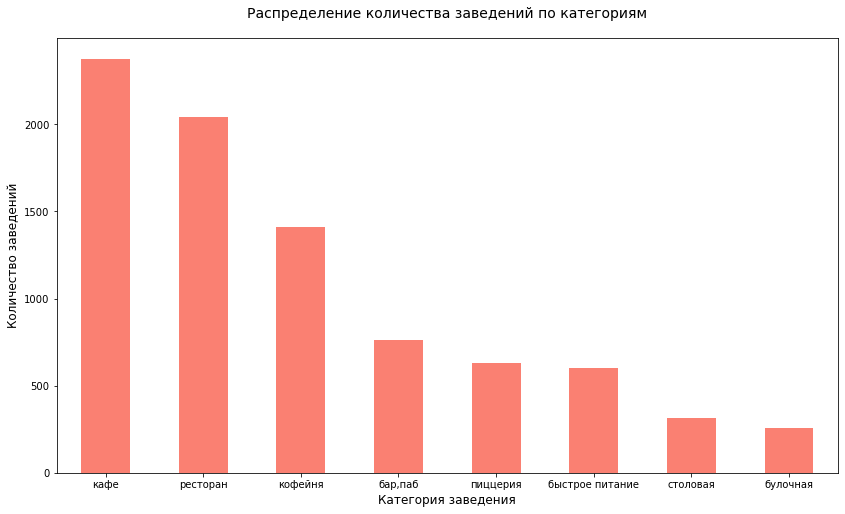

In [81]:
plt.figure(figsize = (14, 8))

vz_1 = df['category'].value_counts().sort_values(ascending=False).plot(
    kind = 'bar',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_1.set_title('Распределение количества заведений по категориям', fontsize = 14, pad = 20)
vz_1.set_xlabel('Категория заведения', fontsize = 12)
vz_1.set_ylabel('Количество заведений', fontsize = 12)

plt.show()

-----------------

---

### Административные районы

Рассмотрим, какие административные районы Москвы присутствуют в данных. Исследуем распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы

In [82]:
df['district'].unique()

array(['северный ао', 'северо-восточный ао', 'северо-западный ао',
       'западный ао', 'центральный ао', 'восточный ао',
       'юго-восточный ао', 'южный ао', 'юго-западный ао'], dtype=object)

In [83]:
df['district'].nunique()

9

In [84]:
df['district'].value_counts()

центральный ао         2242
северный ао             900
северо-восточный ао     891
южный ао                891
западный ао             851
восточный ао            796
юго-восточный ао        714
юго-западный ао         709
северо-западный ао      409
Name: district, dtype: int64

In [85]:
df['district'].value_counts(normalize = True)

центральный ао         0.266809
северный ао            0.107105
северо-восточный ао    0.106034
южный ао               0.106034
западный ао            0.101273
восточный ао           0.094728
юго-восточный ао       0.084970
юго-западный ао        0.084375
северо-западный ао     0.048673
Name: district, dtype: float64

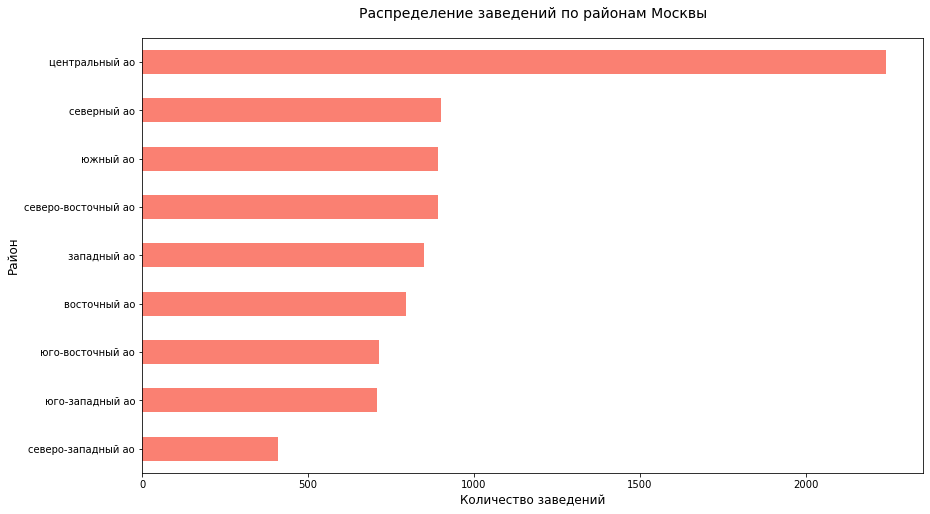

In [86]:
plt.figure(figsize = (14, 8))

vz_2 = df['district'].value_counts().sort_values(ascending=True).plot(
    kind = 'barh',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_2.set_title('Распределение заведений по районам Москвы', fontsize = 14, pad = 20) 
vz_2.set_xlabel('Количество заведений', fontsize = 12)
vz_2.set_ylabel('Район', fontsize = 12) # Когда внутри писала названия и оси нижняя пропадала

plt.show()

С большим отрывом на первом месте центральный административный округ - 2242 заведения, в 2.5 раза превышает следующую за ним позицию. Северный, северо-восточный и южный примерно на одном уровне. Район с самым низким количеством заведений - северо-западный, всего 409 объектов

Рассмотрим детальнее центральный район

In [87]:
zentral_distr_df = df[df['district'] == 'центральный ао']
zentral_distr_df['category'].value_counts()

ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: category, dtype: int64

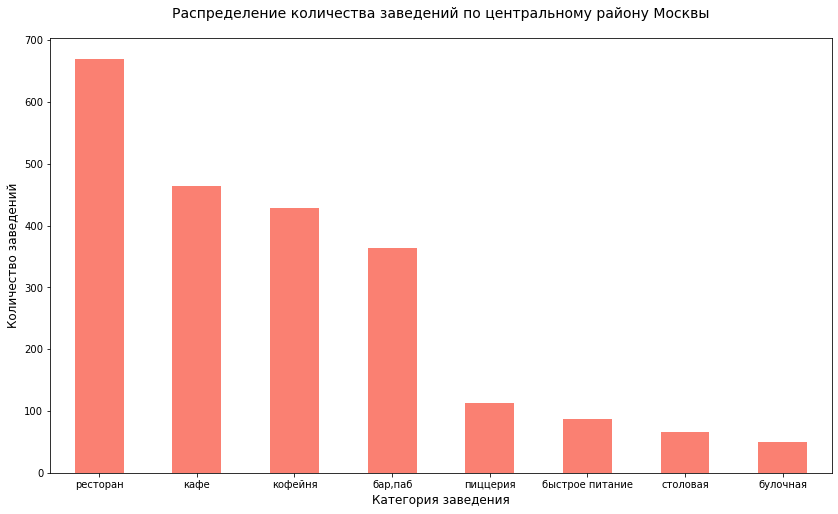

In [88]:
plt.figure(figsize = (14, 8))

vz_3 = zentral_distr_df['category'].value_counts().sort_values(ascending=False).plot(
    kind = 'bar',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_3.set_title('Распределение количества заведений по центральному району Москвы', fontsize = 14, pad = 20)
vz_3.set_xlabel('Категория заведения', fontsize = 12)
vz_3.set_ylabel('Количество заведений', fontsize = 12)

plt.show()

В центральном районе больше всего объектов приходится на рестораны - 670, дальше близко идут кафе и кофейни, бары и пабы. Относительно мало пиццерий, заведений быстрого питания, столовых и булочных

---

### Задача 3

Изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения

In [89]:
df['chain'].value_counts()

False    5201
True     3202
Name: chain, dtype: int64

In [90]:
df['chain'].value_counts(normalize = True)

False    0.618946
True     0.381054
Name: chain, dtype: float64

Посмотрим сколько уникальных названий сетевых заведений

In [91]:
chain_df = df.drop_duplicates(subset = ['name'])

In [92]:
chain_df['chain'].value_counts()

False    4779
True      732
Name: chain, dtype: int64

Визуализируем соотношение сетевых и несетевых заведений в целом по всем данным круговой диаграммой

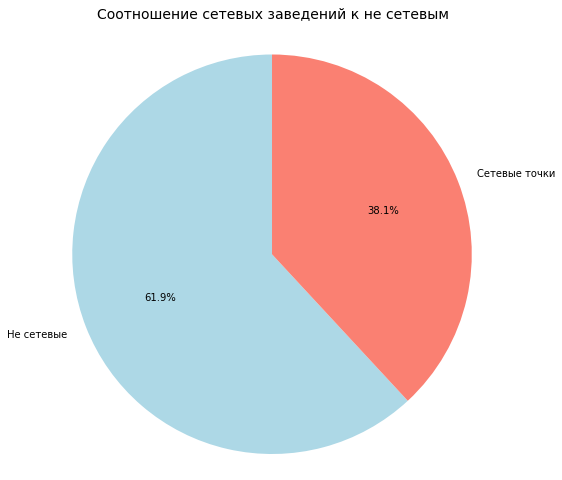

In [93]:
chain_counts = df['chain'].value_counts()

chain_labels_name = {True : 'Сетевые точки', False : 'Не сетевые'}
chain_labels = [chain_labels_name[i] for i in chain_counts.index]

plt.figure(figsize = (8, 8))

vz_4 = plt.pie(
    chain_counts,
    labels = chain_labels,
    colors = ['lightblue', 'salmon'],
    autopct = '%1.1f%%',
    startangle = 90
)

plt.title('Соотношение сетевых заведений к не сетевым', fontsize = 14, pad = 20)
plt.axis('equal')

plt.show()

Не сетевых точек 61,9%, близко к 2/3 от всех заведений общественного питания

Теперь посмотрим на распределение в разрезе категорий заведения

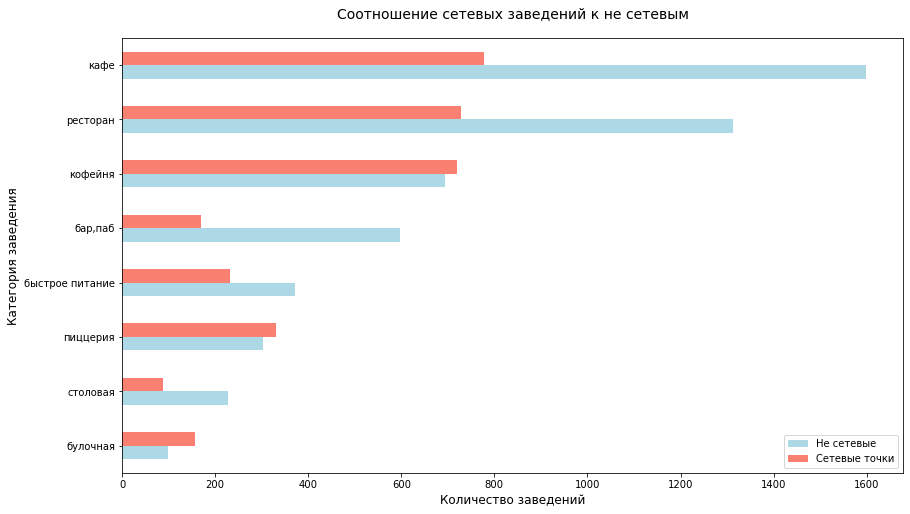

In [94]:
vz_5_df = df.groupby('category')['chain'].value_counts().unstack(fill_value = 0)
vz_5_df_sorted = vz_5_df.sort_values(by = vz_5_df.columns.tolist(), ascending=True)

vz_5 = vz_5_df_sorted.plot(
    kind = 'barh',
    legend = True,
    color = ['lightblue', 'salmon'],
    rot = 0
)

fig = plt.gcf()
fig.set_size_inches(14, 8)

plt.legend(['Не сетевые', 'Сетевые точки'])

vz_5.set_title('Соотношение сетевых заведений к не сетевым', fontsize = 14, pad = 20)
vz_5.set_xlabel('Количество заведений', fontsize = 12)
vz_5.set_ylabel('Категория заведения', fontsize = 12)

plt.show()

И в разрезе районов Москвы

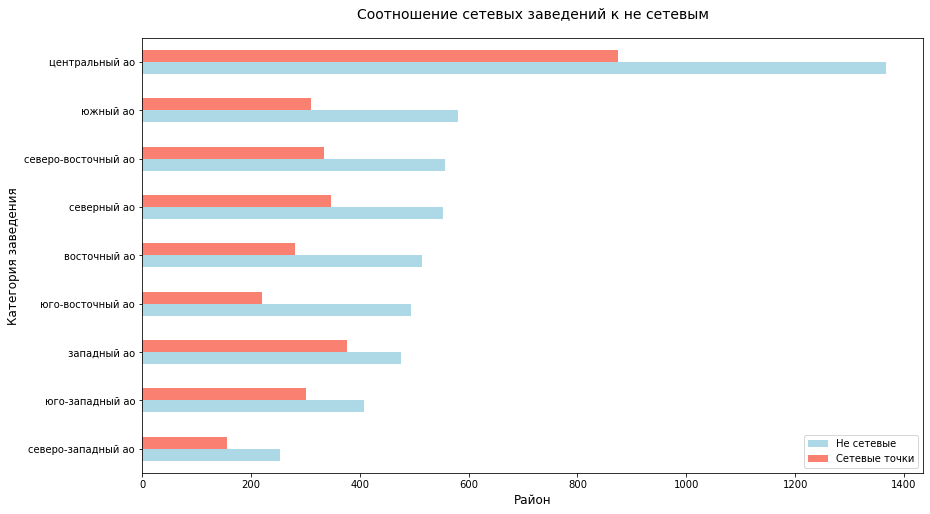

In [95]:
vz_6_df = df.groupby('district')['chain'].value_counts().unstack(fill_value = 0)
vz_6_df_sorted = vz_6_df.sort_values(by = vz_5_df.columns.tolist(), ascending=True)

vz_6 = vz_6_df_sorted.plot(
    kind = 'barh',
    legend = True,
    color = ['lightblue', 'salmon'],
    rot = 0
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

plt.legend(['Не сетевые', 'Сетевые точки'])

vz_6.set_title('Соотношение сетевых заведений к не сетевым', fontsize = 14, pad = 20)
vz_6.set_xlabel('Район', fontsize = 12)
vz_6.set_ylabel('Категория заведения', fontsize = 12)

plt.show()

Не сетевых заведений 61.9%, сетевых - 38.1%. 
Во всех районах города преобладают не сетевые заведения, особенно значительно это видно в восточном, юго-восточном и южном административных округах. По категориям разделение не так явно. Сетевых заведений больше не сетевых в категории булочных. Практически поровну распределились: кофейня, пиццерия. Большое преобладание не сетевых точек в категориях: кафе, ресторан, бар/паб, быстрое питание, столовая.
В абсолютных значениях чаще являются сетевыми кафе, рестораны и кофейни

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1<a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Было бы полезно  посмотреть еще визуально на доли по категориям, ведь количество заведений по ним распределено не равномерно

---

### Количество посадочных мест

Исследуем количество посадочных мест в заведениях

In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8403 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8403 non-null   object 
 1   name               8403 non-null   object 
 2   category           8403 non-null   object 
 3   address            8403 non-null   object 
 4   district           8403 non-null   object 
 5   hours              7867 non-null   object 
 6   rating             8403 non-null   float32
 7   chain              8403 non-null   bool   
 8   seats              8403 non-null   int16  
 9   price              3314 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    8403 non-null   int32  
 12  middle_coffee_cup  8403 non-null   int16  
 13  is_24_7            8403 non-null   bool   
dtypes: bool(2), float32(1), int16(2), int32(1), object(8)
memory usage: 705.7+ KB


In [97]:
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",северный ао,"ежедневно, 10:00–22:00",5.0,False,-1,NaN,NaN,-1,-1,False
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный ао,"ежедневно, 10:00–22:00",4.5,False,4,выше среднего,средний счёт:1500–1600 ₽,1550,-1,False
2,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",северный ао,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,False,45,средние,средний счёт:от 1000 ₽,1000,-1,False
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",северный ао,"ежедневно, 09:00–22:00",5.0,False,-1,NaN,цена чашки капучино:155–185 ₽,-1,170,False
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False


Оставим для работы только записи с известным числом посадочных мест

In [98]:
seats_df = df[df['seats'] > 0]
seats_df = seats_df.reset_index(drop = True)

In [99]:
seats_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4658 entries, 0 to 4657
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4658 non-null   object 
 1   name               4658 non-null   object 
 2   category           4658 non-null   object 
 3   address            4658 non-null   object 
 4   district           4658 non-null   object 
 5   hours              4368 non-null   object 
 6   rating             4658 non-null   float32
 7   chain              4658 non-null   bool   
 8   seats              4658 non-null   int16  
 9   price              2022 non-null   object 
 10  avg_bill           2325 non-null   object 
 11  middle_avg_bill    4658 non-null   int32  
 12  middle_coffee_cup  4658 non-null   int16  
 13  is_24_7            4658 non-null   bool   
dtypes: bool(2), float32(1), int16(2), int32(1), object(8)
memory usage: 354.9+ KB


In [100]:
seats_df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный ао,"ежедневно, 10:00–22:00",4.5,False,4,выше среднего,средний счёт:1500–1600 ₽,1550,-1,False
1,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",северный ао,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,False,45,средние,средний счёт:от 1000 ₽,1000,-1,False
2,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False
3,96ebceb1a09e4e3191133b9fe0379a64,огни города,"бар,паб","москва, клязьминская улица, 9, стр. 3",северный ао,пн 15:00–04:00; вт-вс 15:00–05:00,4.4,False,45,средние,средний счёт:199 ₽,199,-1,False
4,0243288b78024af090b8e947842c969c,mr. уголёк,быстрое питание,"москва, клязьминская улица, 9, стр. 3",северный ао,"пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...",4.7,False,45,средние,средний счёт:200–300 ₽,250,-1,False


Сделаем обзор значений

In [101]:
seats_df['seats'].unique()

array([   4,   45,  148,   79,   65,  102,  180,   96,   25,   46,   40,
        247,   21,    8,   35,  240,   85,   12,   60,  120,   16,   80,
         50,   44,   43,   90,  198,   95,  350,  124,   10,   70,   48,
          6,   98,   30,   52,   20,    2,   18,   22,   15,   28,  300,
         75,   32,  100,  110,  230,  250,  130,   84,  398,   27,  286,
        145,   36,   97,  226,  140,  166,  202,   94,  189,   53,  104,
         72,  131,  105,   55,   17,    1,  115,  310,   77,  160,  320,
         34,  150,  200,  107,   26,   24,   49,  220,  125,    7,  500,
        210,  225,  273,  106,  112,  176,   69,  229,   62,    9,  239,
        246,   42,  188,  174,   14,   76,  232,   68,  625,   83,   92,
        128,  245,   58,   67,   82,    3,   63,   38,   56,  190,   47,
         61,  307,  138,  217,   64,   78,    5,  343,  147,   88,   86,
         74,  420,  170,  132,   93,  326,  126,  143,   29,  252,  481,
         54,  212,  167,  356,   19,   87,   37, 10

In [102]:
seats_df['seats'].nunique()

228

In [103]:
seats_df['seats'].max()

1288

In [104]:
seats_df.loc[seats_df['seats'] == 1288]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
3600,fbf22d98b62a47fbb2a71be3545f16b2,delonixcafe,ресторан,"москва, проспект вернадского, 94, корп. 1",западный ао,"ежедневно, круглосуточно",4.1,False,1288,высокие,средний счёт:1500–2000 ₽,1750,-1,True
3605,c93d20f53072495c9cf2e489914cb8a5,ян примус,ресторан,"москва, проспект вернадского, 121, корп. 1",западный ао,"пн-чт 12:00–00:00; пт,сб 12:00–02:00; вс 12:00...",4.5,True,1288,выше среднего,средний счёт:1500 ₽,1500,-1,False
3637,5925d9677fe24778a27e35ccd88c0a2d,мюнгер,пиццерия,"москва, проспект вернадского, 97, корп. 1",западный ао,"пн-пт 08:00–21:00; сб,вс 10:00–21:00",4.8,True,1288,NaN,NaN,-1,-1,False
3680,0508ba663a4c42d1b5068e51afcc26ef,one price coffee,кофейня,"москва, проспект вернадского, 84, стр. 1",западный ао,"ежедневно, 08:30–20:00",4.3,True,1288,NaN,NaN,-1,-1,False
3693,19a223ff04f74af7a12bd87b77ce468b,гудбар,"бар,паб","москва, проспект вернадского, 97, корп. 1",западный ао,"пн-пт 11:00–23:00; сб,вс 13:00–23:00",4.1,False,1288,средние,средний счёт:700 ₽,700,-1,False
3709,6287fb9811434558a4ada0ae08be9c04,пивной ресторан,"бар,паб","москва, проспект вернадского, 121, корп. 1",западный ао,NaN,4.5,False,1288,NaN,NaN,-1,-1,False
3712,f9e4ec2d1e5946cf83c9564b2d06acd6,японская кухня,ресторан,"москва, проспект вернадского, 121, корп. 1",западный ао,NaN,4.4,True,1288,NaN,NaN,-1,-1,False
3764,6f85ea6419c941208f7deee9194383e1,точка,кафе,"москва, проспект вернадского, 84, стр. 1",западный ао,NaN,4.7,True,1288,NaN,NaN,-1,-1,False
3784,ba5a32dfee6c4661a25c0ea2d39f393d,loft-cafe академия,кафе,"москва, проспект вернадского, 84, стр. 1",западный ао,пн-пт 09:00–20:00; сб 09:00–16:00,3.6,False,1288,NaN,NaN,-1,-1,False
3785,a555f30eac234e6ca28480afa418ed3c,яндекс лавка,ресторан,"москва, проспект вернадского, 51, стр. 1",западный ао,"ежедневно, круглосуточно",4.0,True,1288,NaN,NaN,-1,-1,True


In [105]:
seats_df['seats'].min()

1

In [106]:
seats_df.loc[seats_df['seats'] == 1]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
294,057a045049ff45868a5eb37fbd4e9edf,донер кебаб,быстрое питание,"москва, бульвар яна райниса, 8",северо-западный ао,"ежедневно, круглосуточно",4.2,True,1,NaN,NaN,-1,-1,True
467,4a43088c0beb4bec9e5334e15d4b6100,шаурма,быстрое питание,"москва, путевой проезд, 14, корп. 2",северо-восточный ао,"ежедневно, круглосуточно",4.3,False,1,средние,средний счёт:200–300 ₽,250,-1,True
3858,86768e599aff44b18e237ef6c25adcaa,масала арт,кафе,"москва, улица бутлерова, 24",юго-западный ао,"ежедневно, 10:00–22:00",4.3,False,1,средние,средний счёт:1000 ₽,1000,-1,False
4275,4fb7d6dd007a40cf8ad952fbd3c3ec71,домино'с пицца,пиццерия,"москва, россошанский проезд, 3г",южный ао,"пн-чт 10:00–23:00; пт,сб 10:00–00:00; вс 10:00...",4.2,True,1,NaN,средний счёт:от 500 ₽,500,-1,False


In [107]:
seats_df['seats'].describe()

count    4658.000000
mean      111.589523
std       123.201261
min         1.000000
25%        40.000000
50%        78.500000
75%       143.000000
max      1288.000000
Name: seats, dtype: float64

Всего записей для изучения 4658. Среднее арифмитическое - 111, стандартное отклонение - 123. Медиана 78 сильно меньше среднего 111, это из-за большого разброса и максимальных значений, выше мы увидели, что есть много заведений с максимальным числом посадочных мест. Межквартильный размах намного меньше расстояний от крайних квартилей до минимальных и максимальных значений, значит есть выбросы. Посмотрим на распределение

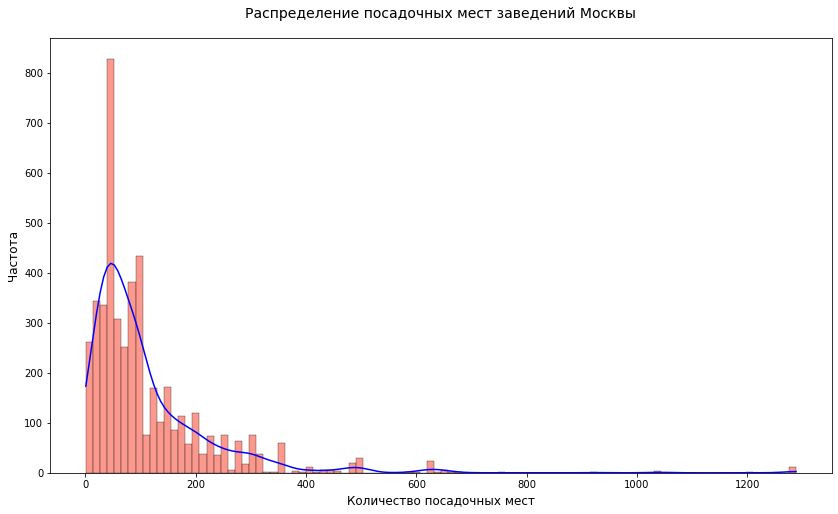

In [108]:
vz_7 = sns.histplot(
    data = seats_df,
    x = 'seats',
    bins = 100,
    color = 'salmon',
    kde = True,
    alpha = 0.8
)

for i in vz_7.get_lines():
    i.set_color('blue'),
    i.set_linewidth(1.5)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_7.set_title('Распределение посадочных мест заведений Москвы', fontsize = 14, pad = 20)
vz_7.set_xlabel('Количество посадочных мест', fontsize = 12)
vz_7.set_ylabel('Частота', fontsize = 12)

plt.show()

График сильно ассиметричный. Пик приходится на значения до 100. В Москве заведения с количеством посадочных мест больше 200 встречаются гораздо реже

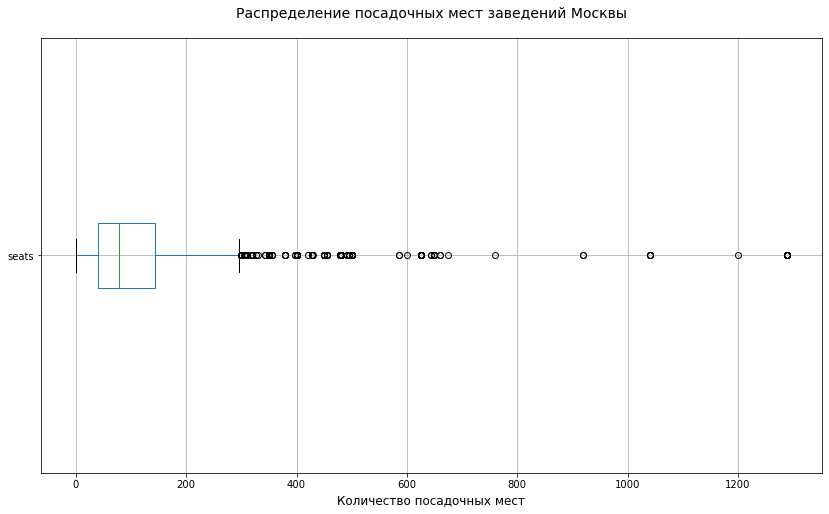

In [109]:
vz_8 = seats_df.boxplot(
    column = 'seats',
    vert = False
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_8.set_title('Распределение посадочных мест заведений Москвы', fontsize = 14, pad = 20)
vz_8.set_xlabel('Количество посадочных мест', fontsize = 12)

plt.show()

В основном количество мест в заведениях до 200, межквартальный размах маленький. Много выбрасов справа. В Москве высокая аренда и плотность заведений - медиана посадочных мест 78, возможно из-за больших банкетных залов и мест премиального класса появляется так много выбросов (хотя по просмотру записей выше, у `one price coffee`, например, тоже 1288 посадочных мест, что подозрительно, возможно это ошибка, или они находятся на фудкорте и посчитали вообще все посадочные места в здании как свои)

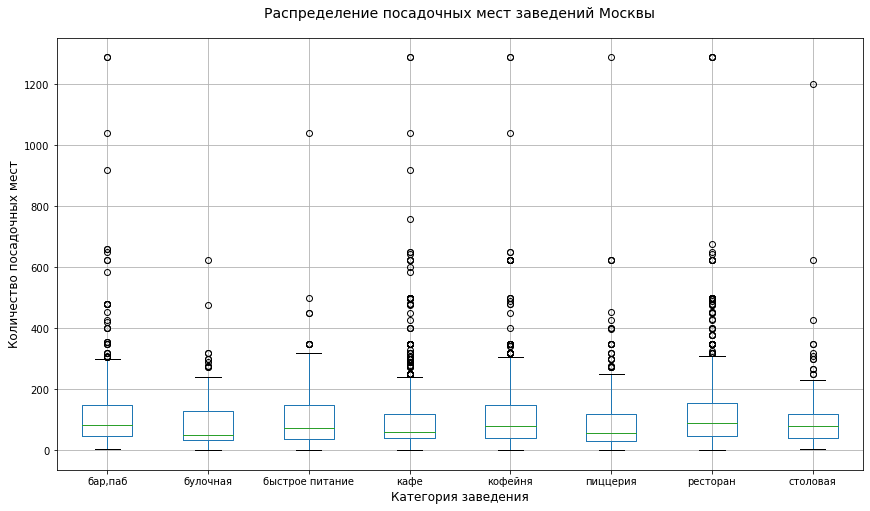

In [110]:
vz_9 = seats_df.boxplot(
    column = 'seats',
    by = 'category',
    vert = True
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_9.set_title('Распределение посадочных мест заведений Москвы', fontsize = 14, pad = 20)
vz_9.set_xlabel('Категория заведения', fontsize = 12)
vz_9.set_ylabel('Количество посадочных мест', fontsize = 12)

fig.suptitle('') # Над графиком была подпись про boxplot
plt.show()

У кафе, ресторанов и пабов очень много выбрасов, возможно из-за разнообразия гастрономической жизни Москвы. Самые адекватные коробки у булочных, столовых и быстрого питения

In [111]:
category_seats = seats_df.groupby('category')['seats'].median()
category_seats

category
бар,паб            84.0
булочная           52.0
быстрое питание    75.0
кафе               60.0
кофейня            80.0
пиццерия           56.0
ресторан           90.0
столовая           80.0
Name: seats, dtype: float64

Общее распределение типичных посадочных мест сохраняется и при рассмотрении отдельных категорий. Медиана лучше отображает положение дел, так как далёкие выбросы тянут среднее сильно вверх. Меньше посадочных мест у пиццерий и булочных. Самая большая медиана у ресторанов. Пабы и бары тоже предлагают посетителям относительно много мест

---

### Рейтинг заведений

Исследуем рейтинг заведений, проверим, сильно ли различаются усреднённые рейтинги для разных типов общепита

В столбце `rating` изначально не было пропусков

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8403 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8403 non-null   object 
 1   name               8403 non-null   object 
 2   category           8403 non-null   object 
 3   address            8403 non-null   object 
 4   district           8403 non-null   object 
 5   hours              7867 non-null   object 
 6   rating             8403 non-null   float32
 7   chain              8403 non-null   bool   
 8   seats              8403 non-null   int16  
 9   price              3314 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    8403 non-null   int32  
 12  middle_coffee_cup  8403 non-null   int16  
 13  is_24_7            8403 non-null   bool   
dtypes: bool(2), float32(1), int16(2), int32(1), object(8)
memory usage: 705.7+ KB


In [113]:
df['rating'].unique()

array([5. , 4.5, 4.6, 4.4, 4.7, 4.8, 4.3, 4.9, 4.2, 4.1, 4. , 3.8, 3.9,
       3.7, 3.6, 2.8, 2.7, 3.1, 1.5, 2. , 1.4, 3.3, 3.5, 3.2, 2.9, 3. ,
       3.4, 2.3, 2.2, 2.5, 2.6, 1.7, 1. , 1.1, 2.4, 1.3, 1.2, 2.1, 1.8,
       1.9, 1.6], dtype=float32)

In [114]:
df['rating'].nunique()

41

In [115]:
df['rating'].min()

1.0

In [116]:
df.loc[df['rating'] == 1]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
1125,a8a79e52ceb84cdca09600e694be2f1a,на мангале,кафе,"москва, проспект мира, 119, стр. 503",северо-восточный ао,"ежедневно, 10:00–21:00",1.0,False,-1,высокие,средний счёт:4000–5000 ₽,4500,-1,False
4222,2c13fae717c749abb88c3c152606efd1,сетунь,ресторан,"москва, 1-й сетуньский проезд, 10с1",западный ао,"ежедневно, 11:00–23:00",1.0,False,-1,NaN,NaN,-1,-1,False
5613,ca26cd67a4a343eb89a928b34b0092f1,тесто и сыр,пиццерия,"москва, рязанский проспект, 2к2",юго-восточный ао,"ежедневно, 10:00–22:00",1.0,False,-1,NaN,NaN,-1,-1,False
5740,2398688dfc4f4f01854e072627a45778,улей,столовая,"москва, западный административный округ, район...",западный ао,пн-пт 10:00–18:00,1.0,False,-1,NaN,NaN,-1,-1,False
5780,a86bc601c412459fb17add8f449f33d7,стар,кафе,"москва, веерная улица, 24г",западный ао,"пн,вт,ср,чт,вс 11:00–22:00",1.0,False,-1,NaN,NaN,-1,-1,False
5808,b6ea23d015e84ed8a39ffa30fa04d1cb,полянка,кафе,"москва, улица удальцова, 75а",западный ао,NaN,1.0,True,40,NaN,NaN,-1,-1,False
5833,e61dd4b8b1d745d9a352247c225beeca,добро пожаловать,ресторан,"москва, рябиновая улица, 47, стр. 1",западный ао,пн-пт 08:00–16:30,1.0,False,80,NaN,NaN,-1,-1,False
6167,df09864c25634e41a61411897dc866b7,универ,кафе,"москва, западный административный округ, район...",западный ао,пн-пт 09:00–20:00; сб 09:00–18:00,1.0,False,-1,NaN,NaN,-1,-1,False
6757,943f9f5bf4454c65837d8f8e6dc2034f,омореморе,ресторан,"москва, ленинский проспект, 108, стр. 1",западный ао,"ежедневно, 09:00–23:00",1.0,True,290,NaN,NaN,-1,-1,False
7629,c281f8193432450fa8bd3b3ecdf72ce8,pho street,кафе,"москва, новоясеневский проспект, 11",юго-западный ао,"ежедневно, 10:00–22:00",1.0,True,70,NaN,NaN,-1,-1,False


Заведений с отвратительным рейтингом не так много? всего 10 (и большинство из них в западном административном округе)

In [117]:
df['rating'].max()

5.0

In [118]:
df.loc[df['rating'] == 5]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",северный ао,"ежедневно, 10:00–22:00",5.0,False,-1,NaN,NaN,-1,-1,False
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",северный ао,"ежедневно, 09:00–22:00",5.0,False,-1,NaN,цена чашки капучино:155–185 ₽,-1,170,False
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False
67,fca6820ccef64456b90326102d6aebb7,штаб квартира,"бар,паб","москва, дубнинская улица, 32",северный ао,"пн-чт 12:30–00:00; пт,сб 12:30–02:00; вс 12:30...",5.0,False,16,средние,цена бокала пива:120–350 ₽,-1,-1,False
102,baf7f65972d54f5a8886962380fd62b8,мята signature алтуфьево,кафе,"москва, улица лескова, 3г",северо-восточный ао,"пн-чт 12:00–03:00; пт,сб 12:00–04:30; вс 12:00...",5.0,False,80,NaN,NaN,-1,-1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7614,70f5fd13324440e083e3741471c463af,чайная,кафе,"москва, новоясеневский проспект, 42",юго-западный ао,NaN,5.0,True,-1,NaN,NaN,-1,-1,False
7865,2c5f901cccec4de588538149a4b367d0,лига шашлыков,быстрое питание,"москва, гурьевский проезд, 21, корп. 1",южный ао,"ежедневно, 10:00–22:00",5.0,False,0,NaN,NaN,-1,-1,False
7999,79d53a4ac2a64ee5a996c7cd0e6b196c,between,кафе,"москва, новоалексеевская улица, 16, корп. 2",северо-восточный ао,NaN,5.0,False,-1,NaN,NaN,-1,-1,False
8056,9ccc3260dd8f485e892459068fad0511,подоконник,кофейня,"москва, варшавское шоссе, 9, стр. 1",южный ао,пн-пт 09:00–17:45,5.0,False,180,NaN,цена чашки капучино:150–180 ₽,-1,165,False


Заведений с идиальным рейтингом 104

In [119]:
df['rating'].describe()

count    8403.000000
mean        4.229838
std         0.470350
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

Минимальная оценка по такой шкале - 1. Среднее и медиана близки по значению, стандартное отклонение не велико

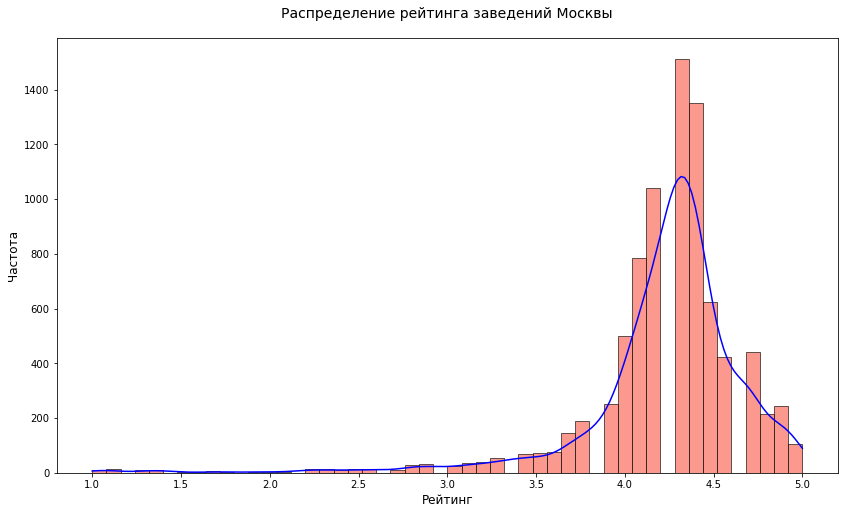

In [120]:
vz_10 = sns.histplot(
    data = df,
    x = 'rating',
    bins = 50,
    color = 'salmon',
    kde = True,
    alpha = 0.8
)

for i in vz_10.get_lines():
    i.set_color('blue'),
    i.set_linewidth(1.5)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_10.set_title('Распределение рейтинга заведений Москвы', fontsize = 14, pad = 20)
vz_10.set_xlabel('Рейтинг', fontsize = 12)
vz_10.set_ylabel('Частота', fontsize = 12)

plt.show()

Пик графика приходится на значения, близкие к 4.5

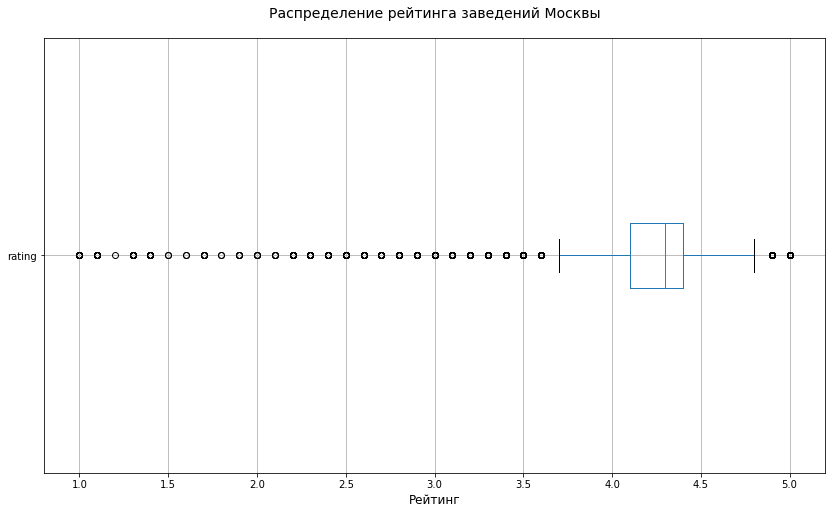

In [121]:
vz_11 = df.boxplot(
    column = 'rating',
    vert = False
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_11.set_title('Распределение рейтинга заведений Москвы', fontsize = 14, pad = 20)
vz_11.set_xlabel('Рейтинг', fontsize = 12)

plt.show()

Коробка разместилась между рейтингом 4 и 4.5. Множество одиночных выбросов слева, посмотрим на распределение по карегорям общепита

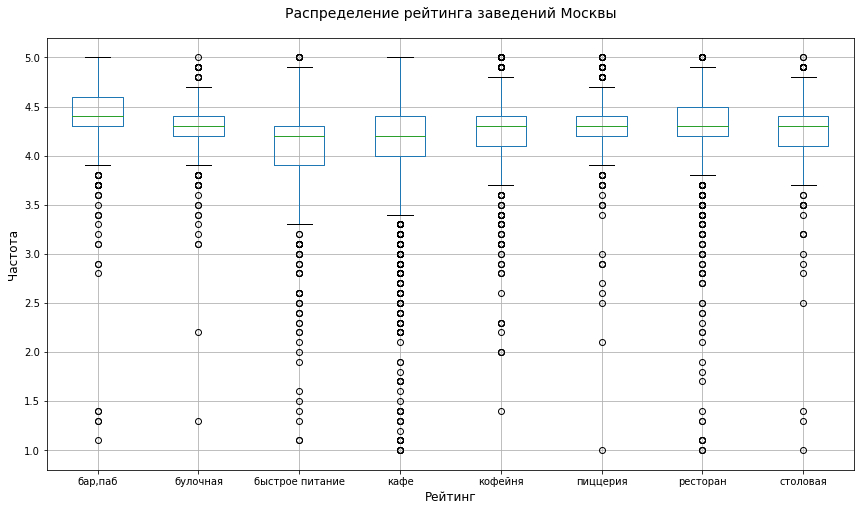

In [122]:
vz_12 = df.boxplot(
    column = 'rating',
    by = 'category',
    vert = True
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_12.set_title('Распределение рейтинга заведений Москвы', fontsize = 14, pad = 20)
vz_12.set_xlabel('Рейтинг', fontsize = 12)
vz_12.set_ylabel('Частота', fontsize = 12)

fig.suptitle('')
plt.show()

У кафе и ресторанов множество выбрасов, как и на коробках распределения посадочных мест. К фастфуду люди более критичны, у этой категории заведений рейтинг в среднем ниже. Самые лояльные посетители у баров и пабов

In [123]:
category_rating = df.groupby('category')['rating'].median()
category_rating

category
бар,паб            4.4
булочная           4.3
быстрое питание    4.2
кафе               4.2
кофейня            4.3
пиццерия           4.3
ресторан           4.3
столовая           4.3
Name: rating, dtype: float32

In [124]:
df['category'].value_counts()

кафе               2377
ресторан           2041
кофейня            1413
бар,паб             765
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

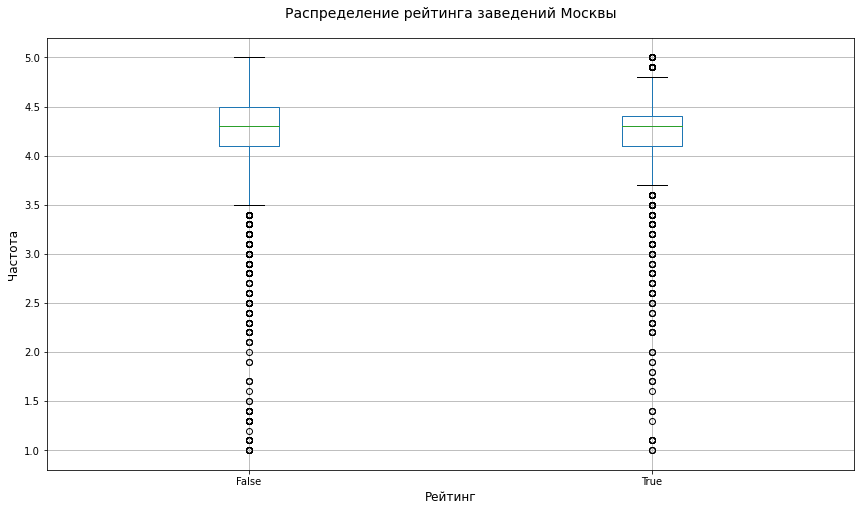

In [125]:
vz_13 = df.boxplot(
    column = 'rating',
    by = 'chain',
    vert = True
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_13.set_title('Распределение рейтинга заведений Москвы', fontsize = 14, pad = 20)
vz_13.set_xlabel('Рейтинг', fontsize = 12)
vz_13.set_ylabel('Частота', fontsize = 12)

fig.suptitle('')
plt.show()

In [126]:
chain_rating = df.groupby('chain')['rating'].median()
chain_rating

chain
False    4.3
True     4.3
Name: rating, dtype: float32

У кафе, ресторанов и кофеен больше всего точек, и разнообразия оценок у них больше. В целом рейтинги находятся в районе 4.3, у фастфуда и кафе 4.3, у баров и пабов 4.4. Отношение заведений к сетевому типу на рейтинг особо не влияет

---

### Корреляция рейтинга

Изучим подробнее, с какими данными показывают самую сильную корреляцию рейтинги заведений

In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8403 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8403 non-null   object 
 1   name               8403 non-null   object 
 2   category           8403 non-null   object 
 3   address            8403 non-null   object 
 4   district           8403 non-null   object 
 5   hours              7867 non-null   object 
 6   rating             8403 non-null   float32
 7   chain              8403 non-null   bool   
 8   seats              8403 non-null   int16  
 9   price              3314 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    8403 non-null   int32  
 12  middle_coffee_cup  8403 non-null   int16  
 13  is_24_7            8403 non-null   bool   
dtypes: bool(2), float32(1), int16(2), int32(1), object(8)
memory usage: 705.7+ KB


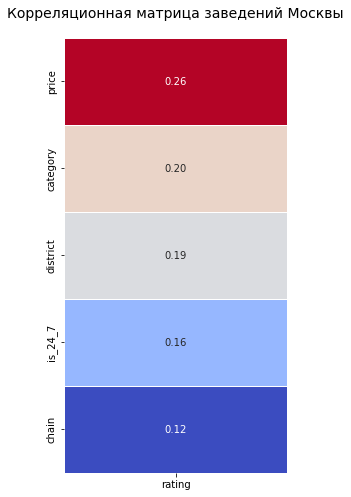

In [128]:
correlation_matrix = df[['category', 'district', 'chain', 'price', 'is_24_7', 'rating']].phik_matrix(interval_cols=['rating'])

vz_14 = correlation_matrix.loc[correlation_matrix.index != 'rating', ['rating']].sort_values(by='rating', ascending=False)

sns.heatmap(
    vz_14,
    annot = True,
    fmt = '.2f',
    cmap = 'coolwarm',
    linewidths = 0.5,
    cbar = False
)

fig = plt.gcf()
fig.set_size_inches(4, 8) 

plt.title('Корреляционная матрица заведений Москвы', fontsize = 14, pad = 20)

plt.show()

На предыдущих этапах показали, что рейтинг не так сильно зависим от того, является ли заведение сетевым или нет, больше влияет категория. По матрице видим, что сильнее всего зависимость рейтинга прослеживается с ценой - 0.26. Проверим связь

In [129]:
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",северный ао,"ежедневно, 10:00–22:00",5.0,False,-1,NaN,NaN,-1,-1,False
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный ао,"ежедневно, 10:00–22:00",4.5,False,4,выше среднего,средний счёт:1500–1600 ₽,1550,-1,False
2,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",северный ао,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,False,45,средние,средний счёт:от 1000 ₽,1000,-1,False
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",северный ао,"ежедневно, 09:00–22:00",5.0,False,-1,NaN,цена чашки капучино:155–185 ₽,-1,170,False
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False


In [130]:
df['price'].unique()

array([nan, 'выше среднего', 'средние', 'высокие', 'низкие'], dtype=object)

In [131]:
df['price'].nunique()

4

In [132]:
df['price'].value_counts()

средние          2117
выше среднего     563
высокие           478
низкие            156
Name: price, dtype: int64

In [133]:
df['price'].describe()

count        3314
unique          4
top       средние
freq         2117
Name: price, dtype: object

Больше всего заведений со средней ценовой политикой - 2117. Точек с низкими ценами всего 156. Очень дорогих заведений - 563

In [134]:
price_rating = df.groupby('price')['rating'].median()
price_rating

price
высокие          4.4
выше среднего    4.4
низкие           4.2
средние          4.3
Name: rating, dtype: float32

У заведений с низкими ценами рейтинги ниже всего - 4.2. Заведения с высокими и самыми высокими ценами - 4.4, но больше всего точек в среднем сегменте - 2117, и рейтинг у них средний - 4.3. Зависимость рейтинга от цен сильнее, чем от других категорий, но всё ещё не такая сильная, баланс по количеству точек и отзывам держат заведения среднего ценового сегмента

---

### Топ-15 популярных сетей в Москве

Сгруппируем данные по названиям заведений, посчитаем значения среднего рейтинга

Нам нужны данные только по сетевым заведениям

In [135]:
chain_top_df = df[df['chain'] == 1]
chain_top_df

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False
13,aea18265b0a0415893f1e796b82568fe,буханка,булочная,"москва, базовская улица, 15, корп. 1",северный ао,"ежедневно, 08:00–22:00",4.8,True,180,NaN,NaN,-1,-1,False
19,feec6bedccae44cb877d99c13f9aa5d7,пекарня,булочная,"москва, ижорский проезд, 5",северный ао,"ежедневно, круглосуточно",4.4,True,-1,NaN,NaN,-1,-1,True
20,1ab5691e4da844d3abadf085e0957852,чебуреки манты,кафе,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",4.3,True,148,NaN,NaN,-1,-1,False
23,78709462f2b3480f825489a5321a3563,буханка,булочная,"москва, лобненская улица, 13к2",северный ао,"ежедневно, 08:00–22:00",4.7,True,-1,NaN,NaN,-1,-1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8317,715f296da82f44bcaf94e26fbeb2202b,беседка,кафе,"москва, кузьминская улица, 10",юго-восточный ао,"ежедневно, 11:00–23:00",4.1,True,-1,NaN,NaN,-1,-1,False
8340,cc23f746c1684b1fbe4bdeecced07a5f,семейный очаг,ресторан,"москва, шоссейная улица, 13",юго-восточный ао,"ежедневно, 12:00–00:00",4.3,True,98,средние,средний счёт:до 1000 ₽,1000,-1,False
8372,47b4a384611948bcb8e8dedde505ed8e,чайхана sabr,ресторан,"москва, улица хлобыстова, 22",юго-восточный ао,"ежедневно, 10:00–00:00",3.9,True,32,средние,средний счёт:150–350 ₽,250,-1,False
8379,aae09f55091e4c1390b61a47267c26e4,лагман хаус,кафе,"москва, новороссийская улица, 14, стр. 2",юго-восточный ао,"ежедневно, 10:00–00:00",4.3,True,40,NaN,NaN,-1,-1,False


In [136]:
chain_top_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3202 entries, 4 to 8404
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 3202 non-null   object 
 1   name               3202 non-null   object 
 2   category           3202 non-null   object 
 3   address            3202 non-null   object 
 4   district           3202 non-null   object 
 5   hours              3086 non-null   object 
 6   rating             3202 non-null   float32
 7   chain              3202 non-null   bool   
 8   seats              3202 non-null   int16  
 9   price              1136 non-null   object 
 10  avg_bill           1465 non-null   object 
 11  middle_avg_bill    3202 non-null   int32  
 12  middle_coffee_cup  3202 non-null   int16  
 13  is_24_7            3202 non-null   bool   
dtypes: bool(2), float32(1), int16(2), int32(1), object(8)
memory usage: 268.9+ KB


In [137]:
top_15 = chain_top_df['name'].value_counts().head(15) 
top_15

шоколадница                            120
домино'с пицца                          76
додо пицца                              74
one price coffee                        71
яндекс лавка                            69
cofix                                   65
prime                                   50
хинкальная                              44
кофепорт                                42
кулинарная лавка братьев караваевых     39
теремок                                 38
чайхана                                 37
cofefest                                32
буханка                                 32
му-му                                   27
Name: name, dtype: int64

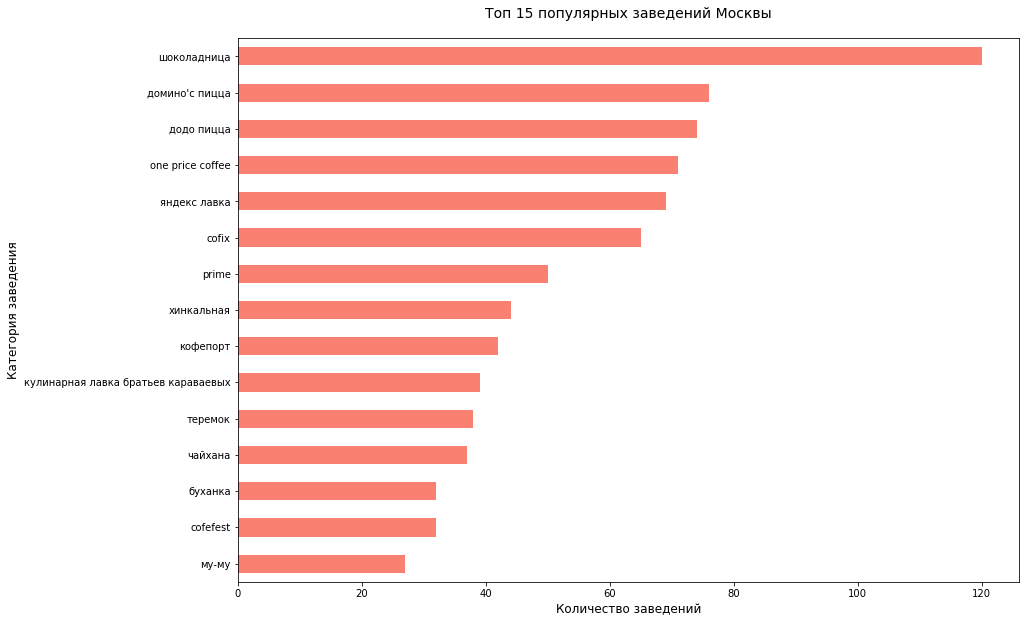

In [138]:
plt.figure(figsize = (14, 10))

vz_15 = chain_top_df['name'].value_counts().head(15).sort_values(ascending=True).plot(
    kind = 'barh',
    legend = False,
    rot = 0,
    color = 'salmon'
)

vz_15.set_title('Топ 15 популярных заведений Москвы', fontsize = 14, pad = 20)
vz_15.set_xlabel('Количество заведений', fontsize = 12)
vz_15.set_ylabel('Категория заведения', fontsize = 12)

plt.show()

Самая популярная сеть с большим отрывом - Шоколадница. У неё 120 точек                          

In [139]:
top_15_chain = chain_top_df['name'].value_counts().head(15).index
top_15_name = df[df['name'].isin(top_15_chain)]
top_15_rating = top_15_name.groupby('name')['rating'].mean().sort_values(ascending=False)
top_15_rating

name
буханка                                4.396875
кулинарная лавка братьев караваевых    4.394872
хинкальная                             4.322727
додо пицца                             4.286487
му-му                                  4.229630
шоколадница                            4.177500
домино'с пицца                         4.171429
кофепорт                               4.147619
теремок                                4.123684
prime                                  4.116000
cofix                                  4.075385
one price coffee                       4.069445
cofefest                               3.984375
чайхана                                3.924324
яндекс лавка                           3.872464
Name: rating, dtype: float32

Самый высокий средний рейтинг у сетей Буханка, Кулинарная лавка братьев караваевых и Хинкальная. У лидера по количеству точек Шоколадницы рейтинг 4.1, из топа 15 по популярности самый низкий рейтинг у Cofefest, Чайханы и Яндекс Лавки

In [140]:
chain_top_15_df = chain_top_df[chain_top_df['name'].isin(top_15_chain)]
chain_top_15_df

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
13,aea18265b0a0415893f1e796b82568fe,буханка,булочная,"москва, базовская улица, 15, корп. 1",северный ао,"ежедневно, 08:00–22:00",4.8,True,180,NaN,NaN,-1,-1,False
23,78709462f2b3480f825489a5321a3563,буханка,булочная,"москва, лобненская улица, 13к2",северный ао,"ежедневно, 08:00–22:00",4.7,True,-1,NaN,NaN,-1,-1,False
32,4e5314c970cc47c58e5d24ee3ee70fa9,додо пицца,пиццерия,"москва, коровинское шоссе, 23, корп. 1",северный ао,"ежедневно, 09:00–23:00",4.3,True,46,NaN,средний счёт:328 ₽,328,-1,False
34,629ac86faa0b4ca49eda1ee27cbda5bb,домино'с пицца,пиццерия,"москва, клязьминская улица, 11, корп. 4",северный ао,"ежедневно, 10:00–23:00",4.2,True,247,NaN,средний счёт:от 500 ₽,500,-1,False
46,bab2d0dc722a45a3b20307527c7337cc,cofefest,кофейня,"москва, улица маршала федоренко, 6с1",северный ао,пн-пт 09:00–19:00,3.6,True,-1,NaN,NaN,-1,-1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7973,4c3dff32a1fc45d28eefe78f72c0df4c,теремок,ресторан,"москва, ореховый бульвар, 15",южный ао,"ежедневно, 10:00–22:00",3.7,True,0,NaN,NaN,-1,-1,False
7974,2a0b895bbfec4aaf85510cb677522e47,хинкальная,ресторан,"москва, улица генерала белова, 23а",южный ао,"ежедневно, 12:00–00:00",3.6,True,60,NaN,NaN,-1,-1,False
7979,ca3f03ddc11d41128968a6586a40e3fe,яндекс лавка,ресторан,"москва, шипиловский проезд, 65, корп. 1",южный ао,"ежедневно, 07:00–00:00",3.5,True,75,NaN,NaN,-1,-1,False
7980,bc4e388dec094056addf94f2e5b6f23a,яндекс лавка,ресторан,"москва, улица маршала захарова, 2",южный ао,"ежедневно, 07:00–00:00",4.0,True,200,NaN,NaN,-1,-1,False


In [141]:
chain_category = chain_top_15_df['category'].value_counts()
chain_category

кофейня            336
ресторан           186
пиццерия           151
кафе               100
булочная            25
быстрое питание     12
бар,паб              4
столовая             2
Name: category, dtype: int64

В основном сети из топа это кофейни - 336, рестораны - 186, и пиццерии - 151

---

### Средний чек

Изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем цены в Центральном административном округе и других чтобы узнать, как удалённость от центра влияет на цены в заведениях

In [142]:
middle_avg_bill_df = df[df['middle_avg_bill'] > 0]
middle_avg_bill_df = middle_avg_bill_df.reset_index(drop = True)
middle_avg_bill_df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный ао,"ежедневно, 10:00–22:00",4.5,False,4,выше среднего,средний счёт:1500–1600 ₽,1550,-1,False
1,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",северный ао,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,False,45,средние,средний счёт:от 1000 ₽,1000,-1,False
2,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный ао,"ежедневно, 10:00–22:00",5.0,True,148,средние,средний счёт:400–600 ₽,500,-1,False
3,96ebceb1a09e4e3191133b9fe0379a64,огни города,"бар,паб","москва, клязьминская улица, 9, стр. 3",северный ао,пн 15:00–04:00; вт-вс 15:00–05:00,4.4,False,45,средние,средний счёт:199 ₽,199,-1,False
4,0243288b78024af090b8e947842c969c,mr. уголёк,быстрое питание,"москва, клязьминская улица, 9, стр. 3",северный ао,"пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...",4.7,False,45,средние,средний счёт:200–300 ₽,250,-1,False


In [143]:
middle_avg_bill_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3148 entries, 0 to 3147
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 3148 non-null   object 
 1   name               3148 non-null   object 
 2   category           3148 non-null   object 
 3   address            3148 non-null   object 
 4   district           3148 non-null   object 
 5   hours              3142 non-null   object 
 6   rating             3148 non-null   float32
 7   chain              3148 non-null   bool   
 8   seats              3148 non-null   int16  
 9   price              2678 non-null   object 
 10  avg_bill           3148 non-null   object 
 11  middle_avg_bill    3148 non-null   int32  
 12  middle_coffee_cup  3148 non-null   int16  
 13  is_24_7            3148 non-null   bool   
dtypes: bool(2), float32(1), int16(2), int32(1), object(8)
memory usage: 239.9+ KB


In [144]:
middle_avg_bill_df['middle_avg_bill'].unique()

array([ 1550,  1000,   500,   199,   250,  1100,   330,  1500,   400,
         245,   425,   900,   240,   225,   328,   300,   345,   230,
         650,   750,  1250,  1750,  2250,   600,   450,   850,  2100,
         349,   200,   120,   269,  1300,  1150,   355,   275,  1200,
         575,   350,   700,   284,   150,   362,   325,  2000,   291,
         280,  2750,  1400,  2500,  2150,  5000,   825,   625,  3250,
         675,   475,  1690,   925,  1050,   340,   950,  1025,   321,
         550,   360,   375,   317,   324,   343,   140,   165,   215,
         549,   175,   313,  1375,   100,   975, 11000,   800,   295,
        3750,  1350,   430,   130,   525,   344,   185,  1800,   875,
         480,   695,   261,  1450,  3000,   180,   404,   235,   366,
         304,  4500,   560,   470,   387,  1850,  1900,   315,   363,
         260,  2900,   210,   190,  2200,   299,  1650,   426,  1175,
        4250,   365,   630,   320,   352,   270,   390,   775,  1600,
        3500,   443,

In [145]:
middle_avg_bill_df['middle_avg_bill'].nunique()

229

In [146]:
middle_avg_bill_df['middle_avg_bill'].value_counts()

1250    247
1000    175
300     148
1500    146
400     134
       ... 
495       1
110       1
660       1
309       1
107       1
Name: middle_avg_bill, Length: 229, dtype: int64

In [147]:
middle_avg_bill_df['middle_avg_bill'].describe()

count     3148.000000
mean       958.358005
std       1009.748800
min         30.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64

In [148]:
middle_avg_bill_df.loc[middle_avg_bill_df['middle_avg_bill'] == 30]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
2874,7a8473e6c5fb40b68f8f2d5aaeecb646,шаурмян у арена,быстрое питание,"москва, краснодарская улица, 47",юго-восточный ао,"ежедневно, 09:00–23:00",3.3,False,2,NaN,средний счёт:от 30 ₽,30,-1,False


In [149]:
middle_avg_bill_df.loc[middle_avg_bill_df['middle_avg_bill'] == 35000]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
2780,07b4e95afe8b4d299f823dc4f9de6df5,кафе,ресторан,"москва, каширское шоссе, 23, стр. 2",южный ао,"ежедневно, круглосуточно",4.1,False,100,высокие,средний счёт:20000–50000 ₽,35000,-1,True


Посмотрим на распределение по районам

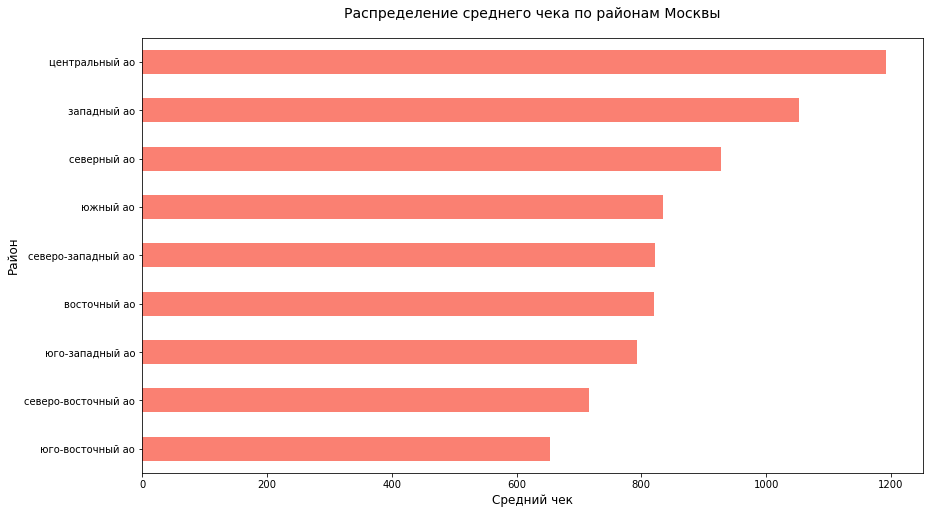

In [150]:
avg_bill_istrict_df = middle_avg_bill_df.groupby('district')['middle_avg_bill'].mean().sort_values(ascending=True)

vz_16 = avg_bill_istrict_df.plot(
    kind = 'barh',
    legend = False,
    rot = 0,
    color = 'salmon'
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_16.set_title('Распределение среднего чека по районам Москвы', fontsize = 14, pad = 20) 
vz_16.set_xlabel('Средний чек', fontsize = 12)
vz_16.set_ylabel('Район', fontsize = 12)

plt.show()

Самый дорогой средний чек в центральном районе, самый низкий - в юго-восточном

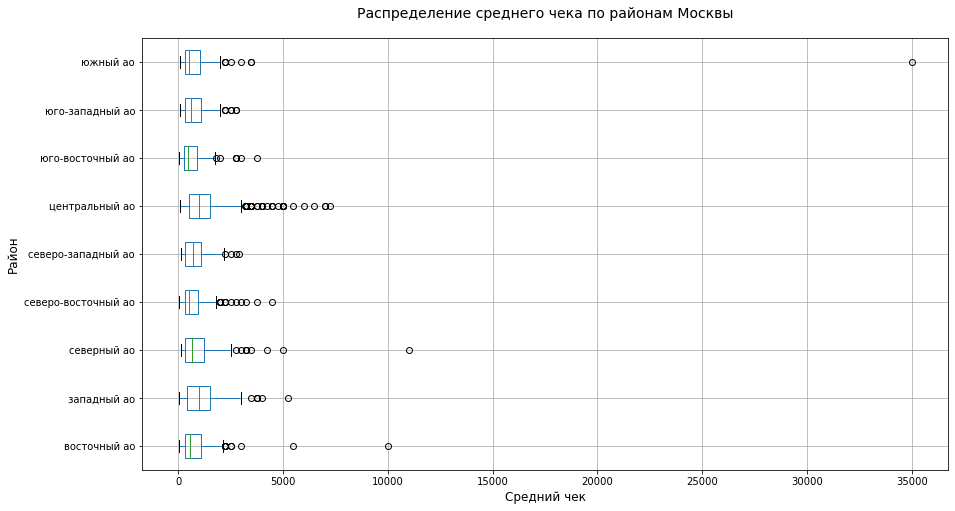

In [151]:
vz_17 = middle_avg_bill_df.boxplot(
    column = 'middle_avg_bill',
    by = 'district',
    vert = False
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_17.set_title('Распределение среднего чека по районам Москвы', fontsize = 14, pad = 20) 
vz_17.set_xlabel('Средний чек', fontsize = 12)
vz_17.set_ylabel('Район', fontsize = 12)

fig.suptitle('')
plt.show()

Из-за сильного выброса в южном районе - 35000, ящики неудобно смотреть. В среднем чеки до 2500 тысяч. Удалим выбросы, чтобы средний чек хотя бы со 100 рублей начинался, так удобнее изучать график

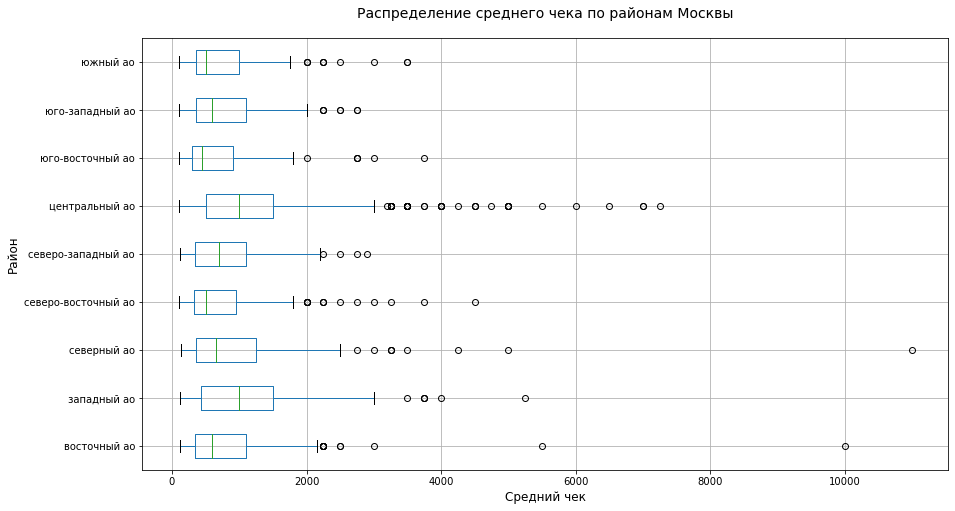

In [152]:
middle_avg_bill_df_2 = middle_avg_bill_df.drop(middle_avg_bill_df[middle_avg_bill_df['middle_avg_bill'] == 35000].index)
middle_avg_bill_df_2 = middle_avg_bill_df_2.drop(middle_avg_bill_df_2[middle_avg_bill_df_2['middle_avg_bill'] == 30].index)
middle_avg_bill_df_2 = middle_avg_bill_df_2.drop(middle_avg_bill_df_2[middle_avg_bill_df_2['middle_avg_bill'] == 50].index)
middle_avg_bill_df_2 = middle_avg_bill_df_2.drop(middle_avg_bill_df_2[middle_avg_bill_df_2['middle_avg_bill'] == 67].index)
middle_avg_bill_df_2 = middle_avg_bill_df_2.drop(middle_avg_bill_df_2[middle_avg_bill_df_2['middle_avg_bill'] == 90].index)

vz_18 = middle_avg_bill_df_2.boxplot(
    column = 'middle_avg_bill',
    by = 'district',
    vert = False
)

fig = plt.gcf()
fig.set_size_inches(14, 8) 

vz_18.set_title('Распределение среднего чека по районам Москвы', fontsize = 14, pad = 20) 
vz_18.set_xlabel('Средний чек', fontsize = 12)
vz_18.set_ylabel('Район', fontsize = 12)

fig.suptitle('')
plt.show()

In [153]:
middle_avg_bill_df_2['middle_avg_bill'].describe()

count     3140.000000
mean       949.529936
std        806.920738
min        100.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      11000.000000
Name: middle_avg_bill, dtype: float64

In [154]:
middle_avg_bill_df_2[middle_avg_bill_df_2['district'] == 'центральный ао' ].describe()

,rating,seats,middle_avg_bill,middle_coffee_cup
count,1058.000000,1058.000000,1058.000000,1058.0
mean,4.402452,72.473535,1193.245747,-1.0
std,0.225888,106.955210,919.503315,0.0
min,2.500000,-1.000000,110.000000,-1.0
25%,4.300000,-1.000000,500.000000,-1.0
50%,4.400000,34.500000,1000.000000,-1.0
75%,4.500000,100.000000,1500.000000,-1.0
max,5.000000,500.000000,7250.000000,-1.0


In [155]:
middle_avg_bill_df_2[middle_avg_bill_df_2['district'] == 'юго-восточный ао' ].describe()

,rating,seats,middle_avg_bill,middle_coffee_cup
count,191.000000,191.000000,191.000000,191.0
mean,4.194242,49.424084,663.481675,-1.0
std,0.405382,75.783023,566.242322,0.0
min,1.600000,-1.000000,107.000000,-1.0
25%,4.100000,-1.000000,300.000000,-1.0
50%,4.300000,20.000000,450.000000,-1.0
75%,4.400000,60.000000,912.500000,-1.0
max,5.000000,500.000000,3750.000000,-1.0


In [156]:
middle_avg_bill_df_2[middle_avg_bill_df_2['district'] == 'южный ао' ].describe()

,rating,seats,middle_avg_bill,middle_coffee_cup
count,313.000000,313.000000,313.000000,313.0
mean,4.231309,75.281150,725.242812,-1.0
std,0.341064,100.936627,542.500400,0.0
min,1.900000,-1.000000,100.000000,-1.0
25%,4.100000,-1.000000,350.000000,-1.0
50%,4.300000,43.000000,500.000000,-1.0
75%,4.400000,96.000000,1000.000000,-1.0
max,5.000000,455.000000,3500.000000,-1.0


Видна корреляция между средним чеком и локацией заведения. Усы справа намного длиннее, чем слева, значит есть достаточно заведений с большим средним чеком, и они тянут значения вправо. Внутри ящиков разброс квартилей тоже бельшой. В каждом районе самые разные заведения предлагают посетителям варианты по ценовому сегменту. Самый высокий средний чек в центральном районе, выбросов много. Самые слабые районы - южный и юго-восточный. Медиана в 2 раза меньше, чем в центральном районе, выбросов мало

---

### Промежуточный вывод

Результаты анализа сходятся с общим представлением о жизни в Москве: в центре дорогой средний чек, больше плотность заведений, больше посадочных мест, много фудкортов, где на одном адресе собрано множество точек, конкуренция высокая. Чем дальше от центра - тем ниже средний чек и количество заведений. Самые слабые районы - южные. Больше всего заведений со средним чеком.  Кафе, рестораны - самые популярные категории общепита. Рейтинги в среднем 4.3, люди лояльнее относятся к барам и пабам, поощряют заведения высокими оценками, ниже среднего оценивают заведения с фастфудом. Несетевых заведений больше, но особой корреляции по этому признаку нет. Главное - цена и категория

## Итоговый вывод и рекомендации

По результатам проведённого исследовательского анализа данных составим рекомендации для заказчика:
1. Данные, собранные для анализа хорошего качества, после предобработки осталось 99% данных (следует внимательнее относиться к фиксации названий и количества посадочных мест)
2. Больше всего заведений, самый высокий средний чек и разнообразие - в центральном районе. Сетевое или не сетевое заведение - явно выделяющийся разницы нет. Посетители лояльны ко все заведениям, особенно к барам и пабам. Предпочтения отдают ресторанам, кафе и кофейням. В меньшенстве булочные и столовые
3. Рекомендации:
    - Центральный район - огромная конкуренция, но большая проходимость и средний чек. Лучше выходить на эту територию при наличии сильной концепции, уникальной идеи. Посетители готовы платить больше и высоко оценивать заведения, но этот рынок в центре Москвы перенасыщен
    - Южные районы - спальные по рейтингам и среднему чеку. Люди здесь оценят что-то простое и доступное
    - В остальных районах конкуренция не такая дикая, как в центре, множество точек в среднем ценовом сегменте. Люди предпочитают кафе, кофейни и небольшие по посадке заведения, готовы проявить лояльность и к барам с пабами

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Анастасия, итоговый вывод, как и весь проект в целом, выполнен классно! Он структурирован и содержит  наиболее значимыерекомендации исходя из каждого пункта работы.
        
Для бизнеса обычно предпочтительна конкретика, например при окрыти в Центре ориентируйтесь на формат... и ценник ....руб. Так ты увеличишь простоту понимания практической пользы твоей работы      
        
Итоговые выводы - важная часть работы и в твоих будующих реальных проектах советую уделять ей особое внимание. Бывают ситуации, когда у руководства нет времени вникать в весь проект и оценка твоих действий будет проводиться именно по ним.    
      